<a href="https://colab.research.google.com/github/sirajulsiddique/Mathematics-for-Data-Science/blob/main/Mathematics_for_Data_Science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# COM7023: Mathematics for Data Science
# Task 1 - Linear Algebra
# Cell 1: Computational Environment

import sys
import numpy as np
import pandas as pd
import sympy as sp
import scipy
import matplotlib
import matplotlib.pyplot as plt

from IPython.display import display

# Verify computational environment
environment = pd.DataFrame({
    "Library": [
        "Python", "NumPy", "Pandas",
        "SymPy", "SciPy", "Matplotlib"
    ],
    "Version": [
        sys.version.split()[0],
        np.__version__,
        pd.__version__,
        sp.__version__,
        scipy.__version__,
        matplotlib.__version__
    ]
})

print("COM7023 - Computational Environment")
display(environment)

print("Environment setup completed successfully.")


COM7023 - Computational Environment


,Library,Version
0,Python,3.13.18
1,NumPy,2.4.6
2,Pandas,2.2.3
3,SymPy,1.14.0
4,SciPy,1.16.3
5,Matplotlib,3.10.0


Environment setup completed successfully.


In [2]:

# Cell 2: Constructing the physiological indicator model

# Define symbolic unknowns
x1, x2, x3, x4 = sp.symbols("x1 x2 x3 x4")

# Coefficient matrix from the assessment brief
A = sp.Matrix([
    [ 2, -1,  1,  0],
    [-1,  3,  0, -1],
    [ 1,  1,  2, -1],
    [ 0, -1,  1,  2]
])

# Physiological indicator vector
X = sp.Matrix([x1, x2, x3, x4])

# Right-hand-side constants
B = sp.Matrix([85, 95, 110, 90])

# Variable descriptions
indicator_names = [
    "Average blood pressure index",
    "Average glucose level",
    "Average cholesterol level",
    "Average BMI-related risk index"
]

# Display original mathematical components
print("Coefficient Matrix (A):")
display(A)

print("Unknown Vector (X):")
display(X)

print("Constant Vector (B):")
display(B)

print("Mathematical Model: AX = B")
display(sp.Eq(A * X, B))


Coefficient Matrix (A):


Matrix([
[ 2, -1, 1,  0],
[-1,  3, 0, -1],
[ 1,  1, 2, -1],
[ 0, -1, 1,  2]])

Unknown Vector (X):


Matrix([
[x1],
[x2],
[x3],
[x4]])

Constant Vector (B):


Matrix([
[ 85],
[ 95],
[110],
[ 90]])

Mathematical Model: AX = B


Eq(Matrix([
[     2*x1 - x2 + x3],
[    -x1 + 3*x2 - x4],
[x1 + x2 + 2*x3 - x4],
[    -x2 + x3 + 2*x4]]), Matrix([
[ 85],
[ 95],
[110],
[ 90]]))

In [3]:

# Cell 3: Equation reconstruction and data integrity

# Reconstruct equations from matrix notation
equations = [
    sp.Eq((A * X)[i], B[i])
    for i in range(A.rows)
]

print("Reconstructed System of Linear Equations")

for i, equation in enumerate(equations, start=1):
    print(f"\nEquation {i}:")
    display(equation)

# Create a structured coefficient table
coefficient_table = pd.DataFrame(
    [list(A.row(i)) for i in range(A.rows)],
    columns=["x1", "x2", "x3", "x4"],
    index=[f"Equation {i}" for i in range(1, 5)]
)

coefficient_table["RHS"] = list(B)

print("\nCoefficient and Constant Audit:")
display(coefficient_table)

# Validate dimensions and numerical entries
assert A.shape == (4, 4), "Invalid coefficient matrix."
assert X.shape == (4, 1), "Invalid unknown vector."
assert B.shape == (4, 1), "Invalid constant vector."

assert all(
    entry.is_number
    for entry in list(A) + list(B)
), "Non-numeric coefficients detected."

print("\nAll dimension and numeric-input checks passed.")


Reconstructed System of Linear Equations

Equation 1:


Eq(2*x1 - x2 + x3, 85)


Equation 2:


Eq(-x1 + 3*x2 - x4, 95)


Equation 3:


Eq(x1 + x2 + 2*x3 - x4, 110)


Equation 4:


Eq(-x2 + x3 + 2*x4, 90)


Coefficient and Constant Audit:


,x1,x2,x3,x4,RHS
Equation 1,2,-1,1,0,85
Equation 2,-1,3,0,-1,95
Equation 3,1,1,2,-1,110
Equation 4,0,-1,1,2,90



All dimension and numeric-input checks passed.


In [4]:

# Cell 4: Matrix properties and solution uniqueness

print("MATRIX PROPERTY ANALYSIS")
print("=" * 55)

# Exact determinant
det_A = A.det()

# Exact symbolic ranks
rank_A = A.rank()
augmented_A = A.row_join(B)
rank_augmented = augmented_A.rank()

# Independent numerical verification
A_numeric = np.array(A.tolist(), dtype=float)

numerical_rank = np.linalg.matrix_rank(A_numeric)
singular_values = np.linalg.svd(
    A_numeric,
    compute_uv=False
)

condition_number = np.linalg.cond(A_numeric)

# Organise results
matrix_diagnostics = pd.DataFrame({
    "Metric": [
        "Number of equations",
        "Number of unknowns",
        "Determinant",
        "Rank of A",
        "Rank of augmented matrix",
        "Numerical rank",
        "Condition number (2-norm)"
    ],
    "Value": [
        A.rows,
        A.cols,
        det_A,
        rank_A,
        rank_augmented,
        numerical_rank,
        round(condition_number, 6)
    ]
})

display(matrix_diagnostics)

print("\nSingular Values:")
print(np.round(singular_values, 6))

# Determine algebraic solution status
if rank_A != rank_augmented:
    status = "Inconsistent system: no solution."

elif rank_A == A.cols:
    status = "Consistent system: unique solution."

else:
    status = "Consistent system: infinitely many solutions."

print("\nAlgebraic Classification:")
print(status)

print("\nImportant distinction:")
print(
    "Algebraic uniqueness does not establish "
    "dynamic physiological stability."
)


MATRIX PROPERTY ANALYSIS


,Metric,Value
0,Number of equations,4
1,Number of unknowns,4
2,Determinant,12
3,Rank of A,4
4,Rank of augmented matrix,4
5,Numerical rank,4
6,Condition number (2-norm),7.924539



Singular Values:
[4.118969 3.071433 1.824892 0.519774]

Algebraic Classification:
Consistent system: unique solution.

Important distinction:
Algebraic uniqueness does not establish dynamic physiological stability.


In [5]:

# GAUSSIAN ELIMINATION SETUP

# Construct an exact augmented matrix
M = A.row_join(B)

# Keep the original matrix unchanged
original_augmented = M.copy()

print("INITIAL AUGMENTED MATRIX [A | B]")
print("=" * 55)

display(M)

print("Matrix dimensions:", M.shape)
print("Initial rank:", M.rank())

# Ensure exact symbolic arithmetic
assert M.shape == (4, 5)
assert all(value.is_Rational for value in M)

print("\nExact arithmetic verified.")
print("Ready for elementary row operations.")


INITIAL AUGMENTED MATRIX [A | B]


Matrix([
[ 2, -1, 1,  0,  85],
[-1,  3, 0, -1,  95],
[ 1,  1, 2, -1, 110],
[ 0, -1, 1,  2,  90]])

Matrix dimensions: (4, 5)
Initial rank: 4

Exact arithmetic verified.
Ready for elementary row operations.


In [6]:

# ELIMINATION USING FIRST PIVOT

print("FORWARD ELIMINATION - STAGE 1")
print("=" * 55)

# First pivot: a11 = 2
pivot_1 = M[0, 0]

print("First pivot =", pivot_1)

# R2 <- R2 + (1/2)R1
factor_21 = -M[1, 0] / pivot_1
M[1, :] = M[1, :] + factor_21 * M[0, :]

print("\nOperation 1: R2 <- R2 + (1/2)R1")
display(M)

# R3 <- R3 - (1/2)R1
factor_31 = -M[2, 0] / pivot_1
M[2, :] = M[2, :] + factor_31 * M[0, :]

print("\nOperation 2: R3 <- R3 - (1/2)R1")
display(M)

# Confirm elimination
assert M[1, 0] == 0
assert M[2, 0] == 0
assert M[3, 0] == 0

print("\nFirst-column elimination verified.")


FORWARD ELIMINATION - STAGE 1
First pivot = 2

Operation 1: R2 <- R2 + (1/2)R1


Matrix([
[2,  -1,   1,  0,    85],
[0, 5/2, 1/2, -1, 275/2],
[1,   1,   2, -1,   110],
[0,  -1,   1,  2,    90]])


Operation 2: R3 <- R3 - (1/2)R1


Matrix([
[2,  -1,   1,  0,    85],
[0, 5/2, 1/2, -1, 275/2],
[0, 3/2, 3/2, -1, 135/2],
[0,  -1,   1,  2,    90]])


First-column elimination verified.


In [7]:

# COMPLETE FORWARD ELIMINATION

print("FORWARD ELIMINATION - STAGE 2")
print("=" * 55)

# Second pivot
pivot_2 = M[1, 1]
print("Second pivot =", pivot_2)

# Eliminate entry in Row 3
factor_32 = -M[2, 1] / pivot_2
M[2, :] = M[2, :] + factor_32 * M[1, :]

print("\nOperation 3: Eliminate Row 3, Column 2")
display(M)

# Eliminate entry in Row 4
factor_42 = -M[3, 1] / pivot_2
M[3, :] = M[3, :] + factor_42 * M[1, :]

print("\nOperation 4: Eliminate Row 4, Column 2")
display(M)

# Third pivot
pivot_3 = M[2, 2]
print("\nThird pivot =", pivot_3)

# Eliminate final lower entry
factor_43 = -M[3, 2] / pivot_3
M[3, :] = M[3, :] + factor_43 * M[2, :]

print("\nOperation 5: Eliminate Row 4, Column 3")
display(M)

# Check upper-triangular structure
U = M[:, :4]
lower_entries = [
    U[i, j]
    for i in range(4)
    for j in range(i)
]

assert all(value == 0 for value in lower_entries)

print("\nUpper-triangular matrix verified.")


FORWARD ELIMINATION - STAGE 2
Second pivot = 5/2

Operation 3: Eliminate Row 3, Column 2


Matrix([
[2,  -1,   1,    0,    85],
[0, 5/2, 1/2,   -1, 275/2],
[0,   0, 6/5, -2/5,   -15],
[0,  -1,   1,    2,    90]])


Operation 4: Eliminate Row 4, Column 2


Matrix([
[2,  -1,   1,    0,    85],
[0, 5/2, 1/2,   -1, 275/2],
[0,   0, 6/5, -2/5,   -15],
[0,   0, 6/5,  8/5,   145]])


Third pivot = 6/5

Operation 5: Eliminate Row 4, Column 3


Matrix([
[2,  -1,   1,    0,    85],
[0, 5/2, 1/2,   -1, 275/2],
[0,   0, 6/5, -2/5,   -15],
[0,   0,   0,    2,   160]])


Upper-triangular matrix verified.


In [8]:

# EXACT BACK-SUBSTITUTION

print("BACK-SUBSTITUTION ANALYSIS")
print("=" * 55)

# Initialise solution vector
solution_exact = sp.zeros(4, 1)

# Solve from last equation to first
for i in reversed(range(4)):

    known_terms = sum(
        U[i, j] * solution_exact[j]
        for j in range(i + 1, 4)
    )

    remaining = M[i, 4] - known_terms

    solution_exact[i] = sp.simplify(
        remaining / U[i, i]
    )

    print(f"\nSolving variable x{i+1}:")
    print("Known-term contribution:", known_terms)
    print("Remaining RHS:", remaining)
    print("Exact solution:", solution_exact[i])

# Display complete exact solution
print("\nFINAL EXACT SOLUTION")
display(solution_exact)

# Present results in a structured table
solution_table = pd.DataFrame({
    "Physiological Indicator": indicator_names,
    "Exact Value": [
        str(value) for value in solution_exact
    ],
    "Decimal Value": [
        float(value) for value in solution_exact
    ]
})

display(solution_table)

print("\nBack-substitution completed.")


BACK-SUBSTITUTION ANALYSIS

Solving variable x4:
Known-term contribution: 0
Remaining RHS: 160
Exact solution: 80

Solving variable x3:
Known-term contribution: -32
Remaining RHS: 17
Exact solution: 85/6

Solving variable x2:
Known-term contribution: -875/12
Remaining RHS: 2525/12
Exact solution: 505/6

Solving variable x1:
Known-term contribution: -70
Remaining RHS: 155
Exact solution: 155/2

FINAL EXACT SOLUTION


Matrix([
[155/2],
[505/6],
[ 85/6],
[   80]])

,Physiological Indicator,Exact Value,Decimal Value
0,Average blood pressure index,155/2,77.500000
1,Average glucose level,505/6,84.166667
2,Average cholesterol level,85/6,14.166667
3,Average BMI-related risk index,80,80.000000



Back-substitution completed.


In [10]:

# INDEPENDENT SYMBOLIC SOLUTION VERIFICATION

print("SYMBOLIC SOLUTION VERIFICATION")
print("=" * 60)

# Method 1: Exact LU decomposition-based solution
solution_lu = A.LUsolve(B)

# Method 2: General symbolic linear system solver
solution_set = sp.linsolve((A, B))
solution_general = sp.Matrix(
    list(next(iter(solution_set)))
)

# Compare with the manual Gaussian elimination result
comparison = pd.DataFrame({
    "Indicator": indicator_names,
    "Gaussian Elimination": [
        str(value) for value in solution_exact
    ],
    "LU Decomposition": [
        str(value) for value in solution_lu
    ],
    "General Solver": [
        str(value) for value in solution_general
    ]
})

display(comparison)

# Verify mathematical equality
assert solution_exact == solution_lu
assert solution_exact == solution_general

# Check determinant using Gaussian elimination pivots
pivots = [U[i, i] for i in range(U.rows)]
pivot_product = sp.prod(pivots)

print("\nElimination pivots:", pivots)
print("Product of pivots:", pivot_product)
print("Original determinant:", A.det())

assert pivot_product == A.det()

print("\nAll symbolic solution checks PASSED.")


SYMBOLIC SOLUTION VERIFICATION


,Indicator,Gaussian Elimination,LU Decomposition,General Solver
0,Average blood pressure index,155/2,155/2,155/2
1,Average glucose level,505/6,505/6,505/6
2,Average cholesterol level,85/6,85/6,85/6
3,Average BMI-related risk index,80,80,80



Elimination pivots: [2, 5/2, 6/5, 2]
Product of pivots: 12
Original determinant: 12

All symbolic solution checks PASSED.


In [12]:

# NUMERICAL SOLUTION AND PRECISION COMPARISON

print("NUMERICAL SOLUTION VERIFICATION")
print("=" * 60)

# Convert exact matrices into NumPy arrays
A_np = np.array(A.tolist(), dtype=np.float64)
B_np = np.array(B.tolist(), dtype=np.float64).reshape(-1)

# Solve independently using NumPy
solution_numpy = np.linalg.solve(A_np, B_np)

# Convert exact symbolic solution into floating-point values
solution_reference = np.array(
    [float(value) for value in solution_exact],
    dtype=np.float64
)

# Calculate numerical differences
absolute_difference = np.abs(
    solution_numpy - solution_reference
)

relative_difference = absolute_difference / np.maximum(
    np.abs(solution_reference),
    np.finfo(np.float64).eps
)

# Construct detailed comparison table
numerical_comparison = pd.DataFrame({
    "Indicator": ["x1", "x2", "x3", "x4"],
    "SymPy Exact (decimal)": solution_reference,
    "NumPy Solution": solution_numpy,
    "Absolute Difference": absolute_difference,
    "Relative Difference": relative_difference
})

display(numerical_comparison)

# Global numerical agreement checks
maximum_difference = np.max(absolute_difference)

print("\nMaximum absolute difference:",
      f"{maximum_difference:.12e}")

np.testing.assert_allclose(
    solution_numpy,
    solution_reference,
    rtol=1e-12,
    atol=1e-12
)

print("\nNumerical agreement verified.")


NUMERICAL SOLUTION VERIFICATION


,Indicator,SymPy Exact (decimal),NumPy Solution,Absolute Difference,Relative Difference
0,x1,77.500000,77.500000,0.000000e+00,0.000000e+00
1,x2,84.166667,84.166667,0.000000e+00,0.000000e+00
2,x3,14.166667,14.166667,1.598721e-14,1.128509e-15
3,x4,80.000000,80.000000,0.000000e+00,0.000000e+00



Maximum absolute difference: 1.598721155460e-14

Numerical agreement verified.


In [14]:

# EQUATION RESIDUAL AND BACKWARD ERROR ANALYSIS

print("SOLUTION RELIABILITY AUDIT")
print("=" * 60)

# Exact residual: A*X - B
exact_residual = A * solution_exact - B

assert exact_residual == sp.zeros(4, 1)

# Floating-point predicted RHS
predicted_rhs = A_np @ solution_numpy

# Numerical residual vector
numerical_residual = predicted_rhs - B_np

# Per-equation verification table
residual_table = pd.DataFrame({
    "Equation": ["E1", "E2", "E3", "E4"],
    "Expected RHS": B_np,
    "Calculated LHS": predicted_rhs,
    "Residual": numerical_residual,
    "Absolute Residual": np.abs(numerical_residual)
})

display(residual_table)

# Compute numerical error metrics
absolute_residual_norm = np.linalg.norm(
    numerical_residual,
    ord=np.inf
)

relative_backward_error = (
    absolute_residual_norm /
    (
        np.linalg.norm(A_np, ord=np.inf)
        * np.linalg.norm(solution_numpy, ord=np.inf)
        + np.linalg.norm(B_np, ord=np.inf)
    )
)

print("\nMaximum Absolute Residual:",
      f"{absolute_residual_norm:.12e}")

print("Relative Backward Error:",
      f"{relative_backward_error:.12e}")

print("Matrix Condition Number:",
      f"{np.linalg.cond(A_np):.6f}")

# Confirm numerical accuracy within tolerance
assert np.allclose(
    predicted_rhs,
    B_np,
    rtol=1e-12,
    atol=1e-12
)

print("\nRESULT: All four equations verified.")
print("Numerical residual checks PASSED.")


SOLUTION RELIABILITY AUDIT


,Equation,Expected RHS,Calculated LHS,Residual,Absolute Residual
0,E1,85.0,85.0,-1.421085e-14,1.421085e-14
1,E2,95.0,95.0,0.000000e+00,0.000000e+00
2,E3,110.0,110.0,-2.842171e-14,2.842171e-14
3,E4,90.0,90.0,-2.842171e-14,2.842171e-14



Maximum Absolute Residual: 2.842170943040e-14
Relative Backward Error: 5.354168181552e-17
Matrix Condition Number: 7.924539

RESULT: All four equations verified.
Numerical residual checks PASSED.


GENERATING MATRIX VISUALISATION


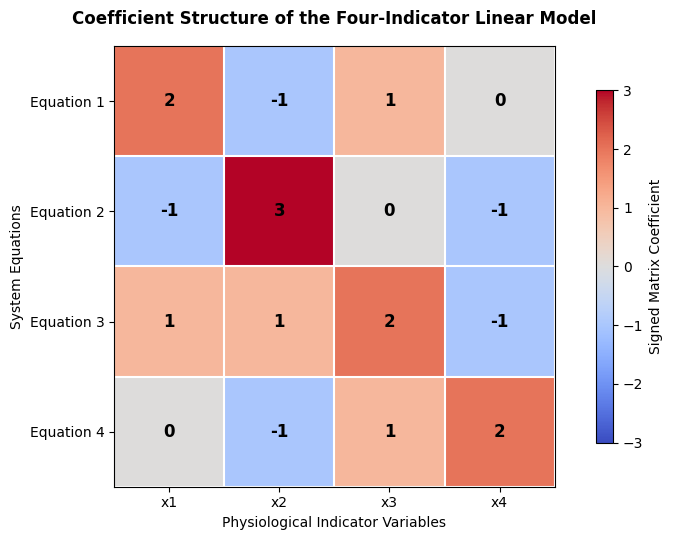


Visualisation exported successfully.
PNG: /content/COM7023_outputs/LA_Fig01_Coefficient_Matrix.png
PDF: /content/COM7023_outputs/LA_Fig01_Coefficient_Matrix.pdf


In [15]:

# COEFFICIENT MATRIX VISUALISATION

import os

print("GENERATING MATRIX VISUALISATION")
print("=" * 60)

# Create output directory in Colab
output_dir = "/content/COM7023_outputs"
os.makedirs(output_dir, exist_ok=True)

# Matrix data
coefficient_values = np.array(
    A.tolist(),
    dtype=float
)

# Create the figure
fig, ax = plt.subplots(figsize=(8.5, 5.5))

image = ax.imshow(
    coefficient_values,
    cmap="coolwarm",
    vmin=-3,
    vmax=3,
    aspect="equal"
)

# Variable and equation labels
ax.set_xticks(range(4))
ax.set_yticks(range(4))

ax.set_xticklabels(["x1", "x2", "x3", "x4"])
ax.set_yticklabels(["Equation 1", "Equation 2",
                    "Equation 3", "Equation 4"])

ax.set_xlabel("Physiological Indicator Variables")
ax.set_ylabel("System Equations")

ax.set_title(
    "Coefficient Structure of the Four-Indicator Linear Model",
    fontsize=12,
    fontweight="bold",
    pad=16
)

# Display exact coefficient values in each cell
for i in range(4):
    for j in range(4):
        value = int(coefficient_values[i, j])

        ax.text(
            j, i, str(value),
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

# Add grid boundaries
ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1.5
)

ax.tick_params(which="minor", bottom=False, left=False)

# Colour bar
colourbar = fig.colorbar(
    image,
    ax=ax,
    shrink=0.80
)

colourbar.set_label("Signed Matrix Coefficient")

plt.tight_layout()

# Export high-resolution files
png_path = os.path.join(
    output_dir,
    "LA_Fig01_Coefficient_Matrix.png"
)

pdf_path = os.path.join(
    output_dir,
    "LA_Fig01_Coefficient_Matrix.pdf"
)

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nVisualisation exported successfully.")
print("PNG:", png_path)
print("PDF:", pdf_path)


In [16]:

# CELL 13: ONE-AT-A-TIME RHS SENSITIVITY ANALYSIS

print("SENSITIVITY ANALYSIS: RHS PERTURBATIONS")
print("=" * 65)

# Baseline solution from the original system
baseline_solution = np.linalg.solve(A_np, B_np)

# Illustrative perturbation level: +1%
perturbation_rate = 0.01

# Store changes in calculated indicator values
delta_matrix = np.zeros((4, 4))

# Store perturbed RHS vectors for later verification
perturbed_rhs_vectors = []

# Store results for a structured table
scenario_records = []

for j in range(4):

    # Copy the original RHS vector
    B_modified = B_np.copy()

    # Increase one equation constant by 1%
    B_modified[j] *= (1 + perturbation_rate)

    # Solve the modified system
    X_modified = np.linalg.solve(
        A_np,
        B_modified
    )

    # Calculate change from baseline
    delta_X = X_modified - baseline_solution

    # Save numerical results
    delta_matrix[:, j] = delta_X
    perturbed_rhs_vectors.append(B_modified)

    scenario_records.append({
        "Scenario": f"Equation {j+1}",
        "Original RHS": B_np[j],
        "Modified RHS": B_modified[j],
        "RHS Increase": B_modified[j] - B_np[j],
        "Change in x1": delta_X[0],
        "Change in x2": delta_X[1],
        "Change in x3": delta_X[2],
        "Change in x4": delta_X[3]
    })

# Convert all results into a DataFrame
sensitivity_table = pd.DataFrame(scenario_records)

print("\nChanges in calculated solutions")
print("Each scenario modifies ONE RHS constant by +1%.")

display(sensitivity_table.round(6))

print("\nSensitivity experiment completed.")


SENSITIVITY ANALYSIS: RHS PERTURBATIONS

Changes in calculated solutions
Each scenario modifies ONE RHS constant by +1%.


,Scenario,Original RHS,Modified RHS,RHS Increase,Change in x1,Change in x2,Change in x3,Change in x4
0,Equation 1,85.0,85.85,0.85,0.850,0.425000,-0.425000,0.425
1,Equation 2,95.0,95.95,0.95,0.475,0.633333,-0.316667,0.475
2,Equation 3,110.0,111.10,1.10,-0.550,-0.366667,0.733333,-0.550
3,Equation 4,90.0,90.90,0.90,0.000,0.150000,0.150000,0.450



Sensitivity experiment completed.


In [17]:

# CELL 14: CONDITIONING AND PERTURBATION VERIFICATION

print("NUMERICAL CONDITIONING AND RELIABILITY")
print("=" * 65)

condition_2norm = np.linalg.cond(A_np, p=2)

reliability_records = []

for j in range(4):

    B_modified = perturbed_rhs_vectors[j]

    delta_B = B_modified - B_np
    delta_X = delta_matrix[:, j]

    # Relative perturbation in RHS
    relative_B_change = (
        np.linalg.norm(delta_B, ord=2)
        / np.linalg.norm(B_np, ord=2)
    )

    # Relative change in the solution
    relative_X_change = (
        np.linalg.norm(delta_X, ord=2)
        / np.linalg.norm(baseline_solution, ord=2)
    )

    # Observed amplification factor
    amplification = (
        relative_X_change / relative_B_change
    )

    # Theoretical upper bound for fixed A
    theoretical_bound = (
        condition_2norm * relative_B_change
    )

    # Check perturbation identity: A(delta X) = delta B
    perturbation_residual = (
        A_np @ delta_X - delta_B
    )

    residual_norm = np.linalg.norm(
        perturbation_residual,
        ord=2
    )

    assert residual_norm < 1e-10

    assert relative_X_change <= (
        theoretical_bound + 1e-10
    )

    reliability_records.append({
        "Scenario": f"Equation {j+1}",
        "Relative RHS Change (%)": relative_B_change * 100,
        "Relative Solution Change (%)": relative_X_change * 100,
        "Amplification Factor": amplification,
        "Condition Bound (%)": theoretical_bound * 100,
        "Residual Norm": residual_norm
    })

# Display verified results
reliability_table = pd.DataFrame(
    reliability_records
)

display(reliability_table.round(8))

print("\n2-Norm Condition Number:",
      f"{condition_2norm:.6f}")

print("\nAll perturbation identity checks PASSED.")
print("All observed changes satisfy the condition bound.")


NUMERICAL CONDITIONING AND RELIABILITY


,Scenario,Relative RHS Change (%),Relative Solution Change (%),Amplification Factor,Condition Bound (%),Residual Norm
0,Equation 1,0.445215,0.801317,1.799841,3.528127,0.0
1,Equation 2,0.497594,0.695554,1.397834,3.943200,0.0
2,Equation 3,0.576161,0.805378,1.397834,4.565811,0.0
3,Equation 4,0.471405,0.354531,0.752073,3.735663,0.0



2-Norm Condition Number: 7.924539

All perturbation identity checks PASSED.
All observed changes satisfy the condition bound.


GENERATING SENSITIVITY HEATMAP


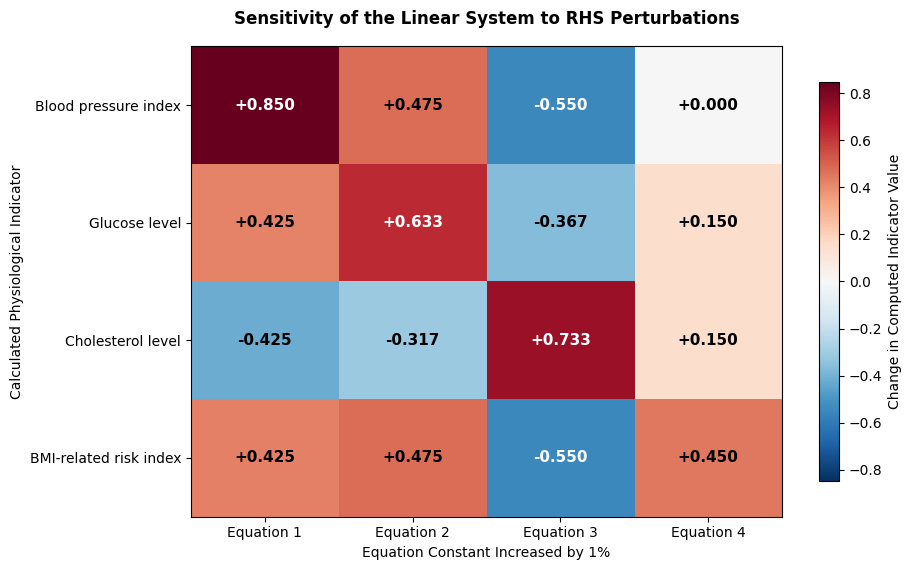


Sensitivity figure exported successfully.
PNG: /content/COM7023_outputs/LA_Fig02_Sensitivity_Heatmap.png
PDF: /content/COM7023_outputs/LA_Fig02_Sensitivity_Heatmap.pdf


In [18]:

# CELL 15: SENSITIVITY HEATMAP

print("GENERATING SENSITIVITY HEATMAP")
print("=" * 65)

# Define indicator labels
short_labels = [
    "Blood pressure index",
    "Glucose level",
    "Cholesterol level",
    "BMI-related risk index"
]

equation_labels = [
    "Equation 1",
    "Equation 2",
    "Equation 3",
    "Equation 4"
]

fig, ax = plt.subplots(figsize=(9.5, 5.8))

# Symmetric scale for positive and negative changes
max_change = np.max(np.abs(delta_matrix))

heatmap = ax.imshow(
    delta_matrix,
    cmap="RdBu_r",
    vmin=-max_change,
    vmax=max_change,
    aspect="auto"
)

ax.set_xticks(range(4))
ax.set_yticks(range(4))

ax.set_xticklabels(equation_labels)
ax.set_yticklabels(short_labels)

ax.set_xlabel("Equation Constant Increased by 1%")
ax.set_ylabel("Calculated Physiological Indicator")

ax.set_title(
    "Sensitivity of the Linear System to RHS Perturbations",
    fontsize=12,
    fontweight="bold",
    pad=16
)

# Annotate all observed solution changes
for i in range(4):
    for j in range(4):

        value = delta_matrix[i, j]

        text_color = (
            "white"
            if abs(value) > 0.6 * max_change
            else "black"
        )

        ax.text(
            j, i,
            f"{value:+.3f}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=text_color
        )

# Colour scale
cbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.85
)

cbar.set_label(
    "Change in Computed Indicator Value"
)

plt.tight_layout()

# Save high-resolution output
sensitivity_png = os.path.join(
    output_dir,
    "LA_Fig02_Sensitivity_Heatmap.png"
)

sensitivity_pdf = os.path.join(
    output_dir,
    "LA_Fig02_Sensitivity_Heatmap.pdf"
)

fig.savefig(
    sensitivity_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    sensitivity_pdf,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSensitivity figure exported successfully.")
print("PNG:", sensitivity_png)
print("PDF:", sensitivity_pdf)


In [19]:

# CELL 16: HEALTH RISK FUNCTION AND DIFFERENTIATION

print("TASK 2: CALCULUS - PATIENT HEALTH RISK")
print("=" * 65)

# Define time variable (days)
t = sp.symbols("t", real=True)

# Risk score function from assessment
R = 3*t**3 - 15*t**2 + 18*t + 70

# First derivative: instantaneous change in risk
R_first = sp.diff(R, t)

# Second derivative: change in the rate of risk
R_second = sp.diff(R_first, t)

print("\nOriginal Risk Function:")
display(sp.Eq(sp.Function("R")(t), R))

print("\nFirst Derivative:")
display(sp.Eq(sp.Symbol("R_prime"), R_first))

print("\nSecond Derivative:")
display(sp.Eq(sp.Symbol("R_double_prime"), R_second))

# Factorise first derivative
print("\nFactorised First Derivative:")
display(sp.factor(R_first))

# Independent verification using first principles
h = sp.symbols("h", real=True)

first_principles = sp.limit(
    (R.subs(t, t+h) - R) / h,
    h, 0
)

assert sp.simplify(first_principles - R_first) == 0

print("\nFirst-principles verification PASSED.")


TASK 2: CALCULUS - PATIENT HEALTH RISK

Original Risk Function:


Eq(R(t), 3*t**3 - 15*t**2 + 18*t + 70)


First Derivative:


Eq(R_prime, 9*t**2 - 30*t + 18)


Second Derivative:


Eq(R_double_prime, 18*t - 30)


Factorised First Derivative:


3*(3*t**2 - 10*t + 6)


First-principles verification PASSED.


In [20]:

# CELL 17: CRITICAL POINT ANALYSIS

print("CRITICAL POINT INVESTIGATION")
print("=" * 65)

# Solve R'(t) = 0
critical_points = sp.solve(
    sp.Eq(R_first, 0), t
)

# Arrange in chronological order
critical_points = sorted(
    critical_points,
    key=lambda value: float(sp.N(value))
)

critical_records = []

for i, point in enumerate(critical_points, 1):

    # Calculate risk at critical point
    risk_value = sp.simplify(R.subs(t, point))

    # Evaluate second derivative
    curvature = sp.simplify(
        R_second.subs(t, point)
    )

    # Classify stationary point
    if curvature < 0:
        classification = "Local Maximum"
    elif curvature > 0:
        classification = "Local Minimum"
    else:
        classification = "Inconclusive"

    critical_records.append({
        "Critical Point": f"CP{i}",
        "Exact Time": str(point),
        "Time (days)": float(point),
        "Exact Risk Score": str(risk_value),
        "Risk Score": float(risk_value),
        "Second Derivative": float(curvature),
        "Classification": classification
    })

critical_table = pd.DataFrame(critical_records)

display(critical_table.round(6))

# Verify stationary conditions
for point in critical_points:
    assert sp.simplify(R_first.subs(t, point)) == 0

print("\nAll critical points verified.")


CRITICAL POINT INVESTIGATION


,Critical Point,Exact Time,Time (days),Exact Risk Score,Risk Score,Second Derivative,Classification
0,CP1,5/3 - sqrt(7)/3,0.784750,14*sqrt(7)/9 + 650/9,76.337835,-15.874508,Local Maximum
1,CP2,sqrt(7)/3 + 5/3,2.548584,650/9 - 14*sqrt(7)/9,68.106609,15.874508,Local Minimum



All critical points verified.


In [21]:

# CELL 18: MONOTONICITY AND RATE-OF-CHANGE ANALYSIS

print("RISK INCREASE AND DECREASE ANALYSIS")
print("=" * 65)

# Use the physically relevant time domain t >= 0
c1, c2 = critical_points

# Select test points from each interval
test_points = [
    c1 / 2,
    (c1 + c2) / 2,
    c2 + 1
]

interval_labels = [
    "0 <= t < CP1",
    "CP1 < t < CP2",
    "t > CP2"
]

trend_records = []

for label, test_point in zip(
    interval_labels, test_points
):

    derivative_value = sp.simplify(
        R_first.subs(t, test_point)
    )

    if derivative_value > 0:
        trend = "Increasing"
    elif derivative_value < 0:
        trend = "Decreasing"
    else:
        trend = "Stationary"

    trend_records.append({
        "Time Interval": label,
        "Test Time (days)": float(test_point),
        "Derivative Value": float(derivative_value),
        "Risk Trend": trend
    })

trend_table = pd.DataFrame(trend_records)

display(trend_table.round(6))

# Evaluate initial risk score
initial_risk = sp.simplify(R.subs(t, 0))

print("\nInitial Risk Score:", initial_risk)
print("Time domain considered: t >= 0")

print("\nRisk trend analysis completed.")


RISK INCREASE AND DECREASE ANALYSIS


,Time Interval,Test Time (days),Derivative Value,Risk Trend
0,0 <= t < CP1,0.392375,7.614378,Increasing
1,CP1 < t < CP2,1.666667,-7.000000,Decreasing
2,t > CP2,3.548584,24.874508,Increasing



Initial Risk Score: 70
Time domain considered: t >= 0

Risk trend analysis completed.


GENERATING PATIENT HEALTH RISK CURVE


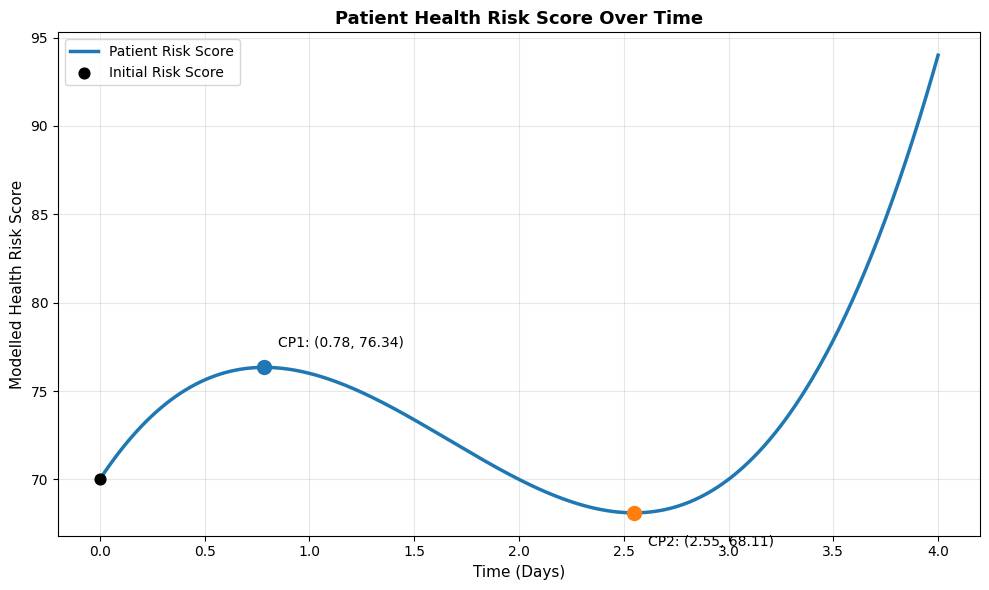


Risk curve generated successfully.
Saved to: /content/COM7023_outputs/CAL_Fig01_Risk_Score_Curve.png


In [22]:

# CELL 19: PATIENT RISK SCORE VISUALISATION

print("GENERATING PATIENT HEALTH RISK CURVE")
print("=" * 65)

# Illustrative observation window: 0 to 4 days
time_values = np.linspace(0, 4, 500)

# Convert symbolic expression to numerical function
risk_function = sp.lambdify(t, R, modules="numpy")

risk_values = risk_function(time_values)

fig, ax = plt.subplots(figsize=(10, 6))

# Main risk curve
ax.plot(
    time_values,
    risk_values,
    linewidth=2.5,
    label="Patient Risk Score"
)

# Mark critical points
for i, point in enumerate(critical_points, 1):

    time_cp = float(point)
    risk_cp = float(R.subs(t, point))

    ax.scatter(
        time_cp,
        risk_cp,
        s=100,
        zorder=5
    )

    ax.annotate(
        f"CP{i}: ({time_cp:.2f}, {risk_cp:.2f})",
        xy=(time_cp, risk_cp),
        xytext=(10, 15 if i == 1 else -24),
        textcoords="offset points",
        fontsize=10
    )

# Starting point
ax.scatter(
    0,
    float(initial_risk),
    color="black",
    s=60,
    label="Initial Risk Score",
    zorder=5
)

ax.set_title(
    "Patient Health Risk Score Over Time",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Time (Days)", fontsize=11)
ax.set_ylabel("Modelled Health Risk Score", fontsize=11)

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()

# Export graph
calculus_png = os.path.join(
    output_dir,
    "CAL_Fig01_Risk_Score_Curve.png"
)

fig.savefig(
    calculus_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nRisk curve generated successfully.")
print("Saved to:", calculus_png)


In [23]:

# CELL 20: INFLECTION POINT AND CURVATURE ANALYSIS

print("INFLECTION POINT AND CURVATURE ANALYSIS")
print("=" * 65)

# Solve R''(t) = 0
inflection_points = sp.solve(R_second, t)

inflection_records = []

for point in inflection_points:

    risk_at_point = sp.simplify(R.subs(t, point))
    slope_at_point = sp.simplify(R_first.subs(t, point))

    inflection_records.append({
        "Exact Time": str(point),
        "Time (Days)": float(point),
        "Risk Score": float(risk_at_point),
        "Instantaneous Rate": float(slope_at_point),
        "Second Derivative": float(R_second.subs(t, point))
    })

inflection_table = pd.DataFrame(inflection_records)

display(inflection_table.round(6))

# Verify curvature changes sign
inflection_time = inflection_points[0]

left_curvature = R_second.subs(
    t, inflection_time - sp.Rational(1, 10)
)

right_curvature = R_second.subs(
    t, inflection_time + sp.Rational(1, 10)
)

assert left_curvature < 0
assert right_curvature > 0

print("\nCurvature before inflection: Negative")
print("Curvature after inflection: Positive")
print("\nInflection point verified.")


INFLECTION POINT AND CURVATURE ANALYSIS


,Exact Time,Time (Days),Risk Score,Instantaneous Rate,Second Derivative
0,5/3,1.666667,72.222222,-7.0,0.0



Curvature before inflection: Negative
Curvature after inflection: Positive

Inflection point verified.


In [24]:

# CELL 21: NUMERICAL DERIVATIVE VALIDATION

print("SYMBOLIC VS NUMERICAL DIFFERENTIATION")
print("=" * 65)

# Numerical functions
f = sp.lambdify(t, R, "numpy")
f_prime = sp.lambdify(t, R_first, "numpy")
f_second = sp.lambdify(t, R_second, "numpy")

# Select points within the illustrative monitoring window
test_times = np.array([
    0.25, 0.75, 1.25,
    5/3, 2.25, 3.0, 3.75
])

# Finite-difference step sizes
h_first = 1e-4
h_second = 1e-3

# Central difference approximation of first derivative
numerical_first = (
    f(test_times + h_first)
    - f(test_times - h_first)
) / (2 * h_first)

# Central difference approximation of second derivative
numerical_second = (
    f(test_times + h_second)
    - 2 * f(test_times)
    + f(test_times - h_second)
) / (h_second ** 2)

# Exact symbolic derivative values
symbolic_first = f_prime(test_times)
symbolic_second = f_second(test_times)

# Calculate absolute errors
first_error = np.abs(symbolic_first - numerical_first)
second_error = np.abs(symbolic_second - numerical_second)

validation_table = pd.DataFrame({
    "Time (Days)": test_times,
    "Symbolic R'(t)": symbolic_first,
    "Numerical R'(t)": numerical_first,
    "First Derivative Error": first_error,
    "Symbolic R''(t)": symbolic_second,
    "Numerical R''(t)": numerical_second,
    "Second Derivative Error": second_error
})

display(validation_table.round(8))

print("\nMaximum First Derivative Error:",
      f"{np.max(first_error):.10e}")

print("Maximum Second Derivative Error:",
      f"{np.max(second_error):.10e}")

# Validate numerical agreement
assert np.max(first_error) < 1e-6
assert np.max(second_error) < 1e-4

print("\nNumerical differentiation checks PASSED.")


SYMBOLIC VS NUMERICAL DIFFERENTIATION


,Time (Days),Symbolic R'(t),Numerical R'(t),First Derivative Error,Symbolic R''(t),Numerical R''(t),Second Derivative Error
0,0.250000,11.0625,11.0625,3.000000e-08,-25.5,-2.550000e+01,1.000000e-08
1,0.750000,0.5625,0.5625,3.000000e-08,-16.5,-1.650000e+01,0.000000e+00
2,1.250000,-5.4375,-5.4375,3.000000e-08,-7.5,-7.500000e+00,0.000000e+00
3,1.666667,-7.0000,-7.0000,3.000000e-08,0.0,-1.000000e-08,1.000000e-08
4,2.250000,-3.9375,-3.9375,3.000000e-08,10.5,1.050000e+01,0.000000e+00
5,3.000000,9.0000,9.0000,3.000000e-08,24.0,2.400000e+01,0.000000e+00
6,3.750000,32.0625,32.0625,3.000000e-08,37.5,3.750000e+01,1.000000e-08



Maximum First Derivative Error: 3.0056867217e-08
Maximum Second Derivative Error: 1.4210854715e-08

Numerical differentiation checks PASSED.


GENERATING DERIVATIVE ANALYSIS FIGURE


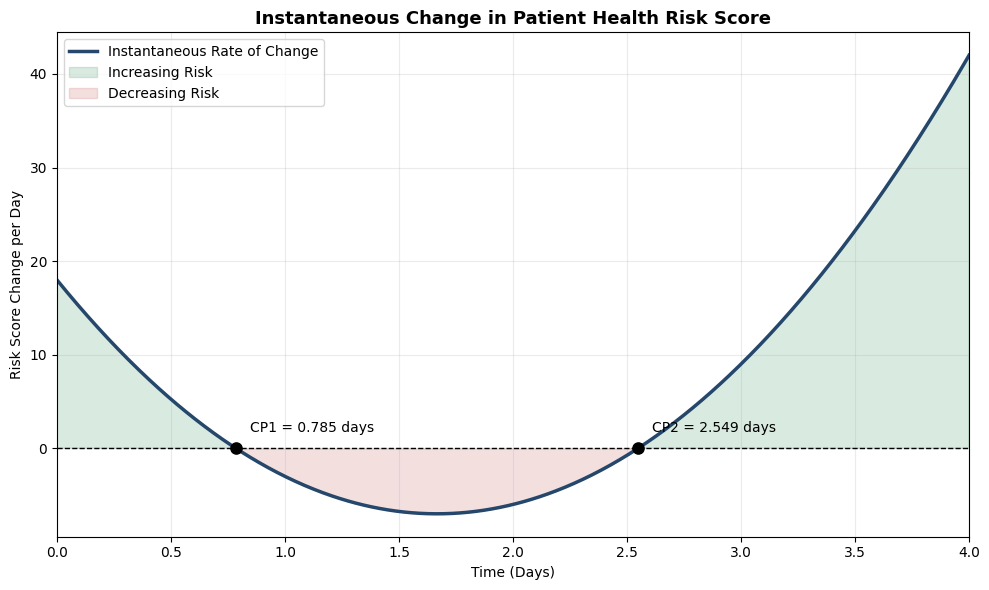

Derivative visualisation saved successfully.
/content/COM7023_outputs/CAL_Fig02_First_Derivative.png


In [25]:

# CELL 22: FIRST DERIVATIVE AND RISK TREND VISUALISATION

print("GENERATING DERIVATIVE ANALYSIS FIGURE")
print("=" * 65)

# Illustrative monitoring period
time_grid = np.linspace(0, 4, 800)

# Evaluate derivative
rate_values = f_prime(time_grid)

fig, ax = plt.subplots(figsize=(10, 6))

# Derivative curve
ax.plot(
    time_grid,
    rate_values,
    color="#24476b",
    linewidth=2.5,
    label="Instantaneous Rate of Change"
)

# Shade positive derivative regions
ax.fill_between(
    time_grid, 0, rate_values,
    where=(rate_values >= 0),
    color="#2e8b57",
    alpha=0.18,
    label="Increasing Risk"
)

# Shade negative derivative regions
ax.fill_between(
    time_grid, 0, rate_values,
    where=(rate_values < 0),
    color="#c44e52",
    alpha=0.18,
    label="Decreasing Risk"
)

# Zero derivative reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

# Mark both critical points
for i, point in enumerate(critical_points, 1):
    cp = float(point)

    ax.scatter(
        cp, 0,
        color="black",
        s=65,
        zorder=5
    )

    ax.annotate(
        f"CP{i} = {cp:.3f} days",
        xy=(cp, 0),
        xytext=(10, 12),
        textcoords="offset points",
        fontsize=10
    )

ax.set_title(
    "Instantaneous Change in Patient Health Risk Score",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Time (Days)")
ax.set_ylabel("Risk Score Change per Day")
ax.set_xlim(0, 4)

ax.grid(alpha=0.25)
ax.legend(loc="upper left")

plt.tight_layout()

# Save visualisation
derivative_path = os.path.join(
    output_dir,
    "CAL_Fig02_First_Derivative.png"
)

fig.savefig(
    derivative_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Derivative visualisation saved successfully.")
print(derivative_path)


OBSERVATION WINDOW AND EXTREMA ANALYSIS


,Time (Days),Risk Score
0,0.000000,70.000000
1,0.784750,76.337835
2,2.548584,68.106609
3,4.000000,94.000000



Minimum risk within [0, 4]:
Time (Days)     2.548584
Risk Score     68.106609

Maximum risk within [0, 4]:
Time (Days)     4.0
Risk Score     94.0


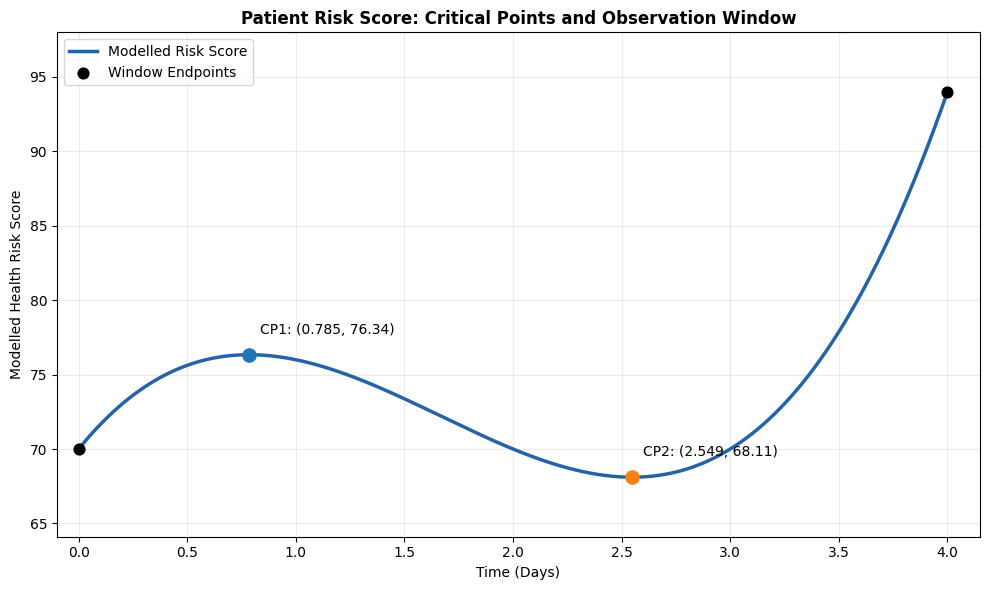


Refined risk curve saved successfully.
/content/COM7023_outputs/CAL_Fig03_Refined_Risk_Curve.png

Note: Global extrema apply only to the
illustrative 0-4 day observation window.


In [26]:

# CELL 23: REFINED RISK CURVE AND EXTREMA ANALYSIS

print("OBSERVATION WINDOW AND EXTREMA ANALYSIS")
print("=" * 65)

# Illustrative window (not specified in the assessment)
start_day = 0
end_day = 4

# Evaluate endpoints and critical points
candidate_times = [
    sp.Integer(start_day),
    *critical_points,
    sp.Integer(end_day)
]

extrema_records = []

for point in candidate_times:
    extrema_records.append({
        "Time (Days)": float(point),
        "Risk Score": float(R.subs(t, point))
    })

extrema_table = pd.DataFrame(extrema_records)

display(extrema_table.round(6))

# Find global extrema within [0, 4]
minimum_row = extrema_table.loc[
    extrema_table["Risk Score"].idxmin()
]

maximum_row = extrema_table.loc[
    extrema_table["Risk Score"].idxmax()
]

print("\nMinimum risk within [0, 4]:")
print(minimum_row.to_string())

print("\nMaximum risk within [0, 4]:")
print(maximum_row.to_string())

# Create corrected figure
plot_t = np.linspace(start_day, end_day, 600)
plot_r = f(plot_t)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    plot_t,
    plot_r,
    color="#2563a6",
    linewidth=2.5,
    label="Modelled Risk Score"
)

# Mark critical points with readable labels
for i, point in enumerate(critical_points, 1):

    cp_t = float(point)
    cp_r = float(R.subs(t, point))

    ax.scatter(
        cp_t, cp_r,
        s=90,
        zorder=5
    )

    ax.annotate(
        f"CP{i}: ({cp_t:.3f}, {cp_r:.2f})",
        xy=(cp_t, cp_r),
        xytext=(8, 15),
        textcoords="offset points",
        fontsize=10
    )

# Mark observation-window endpoints
ax.scatter(
    [start_day, end_day],
    [f(start_day), f(end_day)],
    color="black",
    s=60,
    zorder=5,
    label="Window Endpoints"
)

ax.set_title(
    "Patient Risk Score: Critical Points and Observation Window",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Time (Days)")
ax.set_ylabel("Modelled Health Risk Score")

# Provide sufficient vertical space for annotations
ax.set_xlim(-0.1, 4.15)
ax.set_ylim(
    float(np.min(plot_r)) - 4,
    float(np.max(plot_r)) + 4
)

ax.grid(alpha=0.25)
ax.legend(loc="upper left")

plt.tight_layout()

# Export corrected chart
refined_path = os.path.join(
    output_dir,
    "CAL_Fig03_Refined_Risk_Curve.png"
)

fig.savefig(
    refined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nRefined risk curve saved successfully.")
print(refined_path)

print("\nNote: Global extrema apply only to the")
print("illustrative 0-4 day observation window.")


In [27]:

# CELL 24: NORMAL DISTRIBUTION MODEL

from scipy.stats import norm
from scipy.integrate import quad
from math import erf, sqrt

print("TASK 3: PROBABILITY - HEALTH RISK PREDICTION ERRORS")
print("=" * 65)

# Parameters provided in the assessment
mu_error = 0.0
sigma_error = 4.0

# Define the theoretical probability distribution
error_distribution = norm(
    loc=mu_error,
    scale=sigma_error
)

# Theoretical distribution properties
distribution_properties = pd.DataFrame({
    "Property": [
        "Distribution",
        "Mean",
        "Standard Deviation",
        "Variance",
        "Median",
        "Skewness",
        "Excess Kurtosis"
    ],
    "Value": [
        "Normal",
        mu_error,
        sigma_error,
        sigma_error**2,
        error_distribution.median(),
        error_distribution.stats(moments="s"),
        error_distribution.stats(moments="k")
    ]
})

display(distribution_properties)

# Validate total probability by numerical integration
total_probability, integration_error = quad(
    error_distribution.pdf,
    -np.inf,
    np.inf
)

print("\nTotal Integrated Probability:",
      f"{total_probability:.12f}")

print("Integration Error Estimate:",
      f"{integration_error:.3e}")

assert np.isclose(total_probability, 1.0)

print("\nNormal distribution validation PASSED.")


TASK 3: PROBABILITY - HEALTH RISK PREDICTION ERRORS


,Property,Value
0,Distribution,Normal
1,Mean,0.0
2,Standard Deviation,4.0
3,Variance,16.0
4,Median,0.0
5,Skewness,0.0
6,Excess Kurtosis,0.0



Total Integrated Probability: 1.000000000000
Integration Error Estimate: 4.390e-10

Normal distribution validation PASSED.


In [28]:

# CELL 25: Z-SCORES AND CENTRAL PROBABILITIES

print("STANDARD NORMAL PROBABILITY ANALYSIS")
print("=" * 65)

thresholds = [4, 8, 12]

central_probability_records = []

for threshold in thresholds:

    # Convert boundaries into Z-scores
    z_lower = (-threshold - mu_error) / sigma_error
    z_upper = (threshold - mu_error) / sigma_error

    # Cumulative probabilities
    cdf_lower = norm.cdf(z_lower)
    cdf_upper = norm.cdf(z_upper)

    # Probability within the threshold
    probability_within = cdf_upper - cdf_lower

    # Complementary outside probability
    probability_outside = 1 - probability_within

    central_probability_records.append({
        "Error Range": f"±{threshold} units",
        "Lower Z": z_lower,
        "Upper Z": z_upper,
        "P(Within Range)": probability_within,
        "Within (%)": probability_within * 100,
        "P(Outside Range)": probability_outside,
        "Outside (%)": probability_outside * 100
    })

central_probability_table = pd.DataFrame(
    central_probability_records
)

display(central_probability_table.round(8))

print("\nAll central probability calculations completed.")


STANDARD NORMAL PROBABILITY ANALYSIS


,Error Range,Lower Z,Upper Z,P(Within Range),Within (%),P(Outside Range),Outside (%)
0,±4 units,-1.0,1.0,0.682689,68.268949,0.317311,31.731051
1,±8 units,-2.0,2.0,0.954500,95.449974,0.045500,4.550026
2,±12 units,-3.0,3.0,0.997300,99.730020,0.002700,0.269980



All central probability calculations completed.


In [29]:

# CELL 26: TAIL PROBABILITIES AND CROSS-VALIDATION

print("EXTREME PREDICTION ERROR ANALYSIS")
print("=" * 65)

verification_records = []

for threshold in thresholds:

    # Positive error tail
    positive_tail = error_distribution.sf(threshold)

    # Negative error tail
    negative_tail = error_distribution.cdf(-threshold)

    # Combined probability of extreme absolute errors
    two_sided_probability = positive_tail + negative_tail

    # Independent numerical integration
    left_area, _ = quad(
        error_distribution.pdf,
        -np.inf,
        -threshold
    )

    right_area, _ = quad(
        error_distribution.pdf,
        threshold,
        np.inf
    )

    integrated_probability = left_area + right_area

    # Independent error-function calculation
    z = threshold / sigma_error

    erf_probability = 1 - erf(z / sqrt(2))

    # Verify all three approaches
    assert np.isclose(
        two_sided_probability,
        integrated_probability,
        atol=1e-12
    )

    assert np.isclose(
        two_sided_probability,
        erf_probability,
        atol=1e-12
    )

    verification_records.append({
        "Threshold": f"|Error| > {threshold}",
        "Negative Tail": negative_tail,
        "Positive Tail": positive_tail,
        "SciPy Two-Tail": two_sided_probability,
        "Numerical Integration": integrated_probability,
        "Error Function Result": erf_probability,
        "Probability (%)": two_sided_probability * 100
    })

tail_probability_table = pd.DataFrame(
    verification_records
)

display(tail_probability_table.round(9))

# Central 95% theoretical coverage interval
lower_95, upper_95 = error_distribution.interval(0.95)

print("\nCentral 95% Prediction Error Interval:")
print(f"[{lower_95:.6f}, {upper_95:.6f}]")

print("\nIndependent probability verification PASSED.")


EXTREME PREDICTION ERROR ANALYSIS


,Threshold,Negative Tail,Positive Tail,SciPy Two-Tail,Numerical Integration,Error Function Result,Probability (%)
0,|Error| > 4,0.158655,0.158655,0.317311,0.317311,0.317311,31.731051
1,|Error| > 8,0.022750,0.022750,0.045500,0.045500,0.045500,4.550026
2,|Error| > 12,0.001350,0.001350,0.002700,0.002700,0.002700,0.269980



Central 95% Prediction Error Interval:
[-7.839856, 7.839856]

Independent probability verification PASSED.


GENERATING PREDICTION ERROR DISTRIBUTION


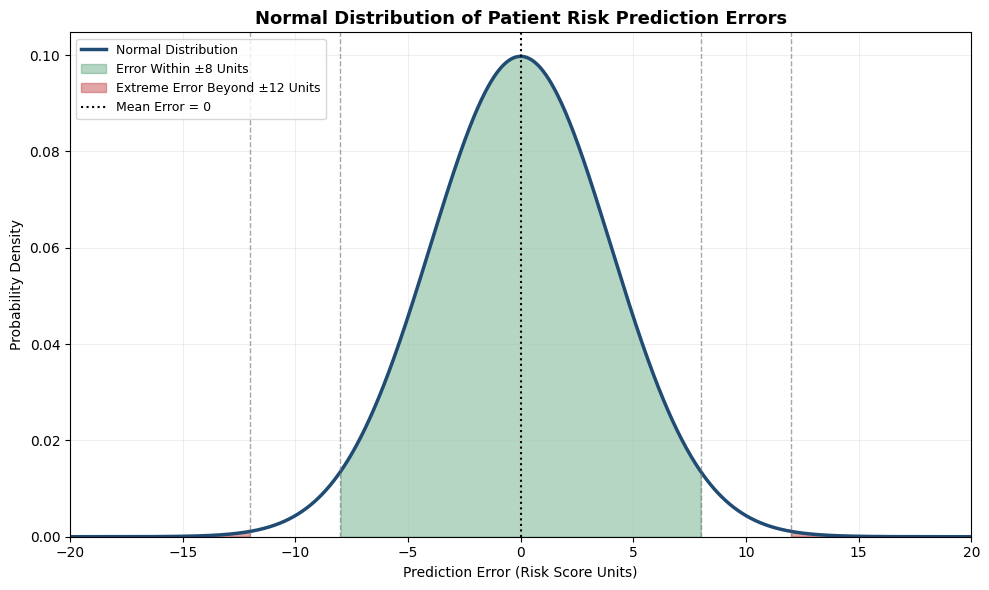


Normal distribution figure saved.
/content/COM7023_outputs/PROB_Fig01_Normal_Distribution.png


In [30]:

# CELL 27: NORMAL DISTRIBUTION VISUALISATION

import os

print("GENERATING PREDICTION ERROR DISTRIBUTION")
print("=" * 65)

output_dir = "/content/COM7023_outputs"
os.makedirs(output_dir, exist_ok=True)

# Distribution plotting domain
error_values = np.linspace(-20, 20, 1200)

# Probability density values
density_values = error_distribution.pdf(error_values)

fig, ax = plt.subplots(figsize=(10, 6))

# Main probability density curve
ax.plot(
    error_values,
    density_values,
    color="#204b73",
    linewidth=2.5,
    label="Normal Distribution"
)

# Highlight central region: -8 to +8
central_mask = (
    (error_values >= -8) &
    (error_values <= 8)
)

ax.fill_between(
    error_values,
    0,
    density_values,
    where=central_mask,
    color="#2e8b57",
    alpha=0.35,
    label="Error Within ±8 Units"
)

# Highlight extreme tails beyond ±12
extreme_mask = (
    (error_values <= -12) |
    (error_values >= 12)
)

ax.fill_between(
    error_values,
    0,
    density_values,
    where=extreme_mask,
    color="#c44e52",
    alpha=0.5,
    label="Extreme Error Beyond ±12 Units"
)

# Draw threshold reference lines
for boundary in [-12, -8, 8, 12]:
    ax.axvline(
        boundary,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.7
    )

# Distribution centre
ax.axvline(
    mu_error,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Mean Error = 0"
)

ax.set_title(
    "Normal Distribution of Patient Risk Prediction Errors",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Prediction Error (Risk Score Units)")
ax.set_ylabel("Probability Density")

ax.set_xlim(-20, 20)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="upper left")

plt.tight_layout()

# Save high-resolution image
probability_path = os.path.join(
    output_dir,
    "PROB_Fig01_Normal_Distribution.png"
)

fig.savefig(
    probability_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nNormal distribution figure saved.")
print(probability_path)


In [31]:

# CELL 28: MONTE CARLO SIMULATION
# Synthetic data generated from the assumed normal model

from scipy.stats import skew, kurtosis

print("MONTE CARLO SIMULATION OF PREDICTION ERRORS")
print("=" * 65)

# Reproducible random number generation
random_seed = 7023
rng = np.random.default_rng(random_seed)

# Simulation sample size
n_simulations = 200_000

# Generate synthetic errors from N(0, 4^2)
simulated_errors = rng.normal(
    loc=mu_error,
    scale=sigma_error,
    size=n_simulations
)

# Calculate descriptive statistics
simulation_summary = pd.DataFrame({
    "Statistic": [
        "Number of simulations",
        "Theoretical mean",
        "Simulated mean",
        "Theoretical standard deviation",
        "Simulated standard deviation",
        "Simulated median",
        "Simulated skewness",
        "Simulated excess kurtosis",
        "Minimum simulated error",
        "Maximum simulated error"
    ],
    "Value": [
        n_simulations,
        mu_error,
        np.mean(simulated_errors),
        sigma_error,
        np.std(simulated_errors, ddof=1),
        np.median(simulated_errors),
        skew(simulated_errors),
        kurtosis(simulated_errors),
        np.min(simulated_errors),
        np.max(simulated_errors)
    ]
})

display(simulation_summary.round(6))

# Check basic simulation integrity
assert len(simulated_errors) == n_simulations
assert np.all(np.isfinite(simulated_errors))

print("\nSimulation Integrity Check: PASSED")
print("Random Seed:", random_seed)
print("Synthetic Observations:", n_simulations)

print("\nNote: These are simulated errors, not patient data.")


MONTE CARLO SIMULATION OF PREDICTION ERRORS


,Statistic,Value
0,Number of simulations,200000.000000
1,Theoretical mean,0.000000
2,Simulated mean,-0.000162
3,Theoretical standard deviation,4.000000
4,Simulated standard deviation,3.991955
5,Simulated median,0.004885
6,Simulated skewness,-0.000505
7,Simulated excess kurtosis,-0.007841
8,Minimum simulated error,-18.402698
9,Maximum simulated error,15.747102



Simulation Integrity Check: PASSED
Random Seed: 7023
Synthetic Observations: 200000

Note: These are simulated errors, not patient data.


In [32]:

# CELL 29: SIMULATED VS THEORETICAL PROBABILITIES

print("MONTE CARLO PROBABILITY VERIFICATION")
print("=" * 65)

# Wilson confidence interval for simulated proportions
def wilson_interval(successes, n, confidence=0.95):

    z = norm.ppf((1 + confidence) / 2)
    p_hat = successes / n

    denominator = 1 + z**2 / n

    centre = (
        p_hat + z**2 / (2*n)
    ) / denominator

    margin = (
        z / denominator
        * np.sqrt(
            p_hat*(1-p_hat)/n
            + z**2/(4*n**2)
        )
    )

    return centre - margin, centre + margin


probability_comparisons = []

for threshold in thresholds:

    # Define central and extreme-error events
    within_event = np.abs(simulated_errors) <= threshold
    outside_event = np.abs(simulated_errors) > threshold

    # Calculate exact theoretical probabilities
    theoretical_within = (
        error_distribution.cdf(threshold)
        - error_distribution.cdf(-threshold)
    )

    theoretical_outside = (
        error_distribution.sf(threshold)
        + error_distribution.cdf(-threshold)
    )

    events = [
        ("Within", within_event, theoretical_within),
        ("Outside", outside_event, theoretical_outside)
    ]

    for event_name, event_mask, theoretical_p in events:

        count = int(np.sum(event_mask))
        simulated_p = count / n_simulations

        lower_ci, upper_ci = wilson_interval(
            count, n_simulations
        )

        probability_comparisons.append({
            "Event": f"{event_name} ±{threshold}",
            "Observed Count": count,
            "Theoretical (%)": theoretical_p * 100,
            "Simulated (%)": simulated_p * 100,
            "Difference (pp)": (
                simulated_p - theoretical_p
            ) * 100,
            "MC CI Lower (%)": lower_ci * 100,
            "MC CI Upper (%)": upper_ci * 100
        })

# Create comparison table
mc_probability_table = pd.DataFrame(
    probability_comparisons
)

display(mc_probability_table.round(6))

print("\nMonte Carlo comparison completed.")

print(
    "Confidence intervals describe simulation "
    "sampling uncertainty, not clinical uncertainty."
)


MONTE CARLO PROBABILITY VERIFICATION


,Event,Observed Count,Theoretical (%),Simulated (%),Difference (pp),MC CI Lower (%),MC CI Upper (%)
0,Within ±4,136621,68.268949,68.3105,0.041551,68.106242,68.514055
1,Outside ±4,63379,31.731051,31.6895,-0.041551,31.485945,31.893758
2,Within ±8,191010,95.449974,95.5050,0.055026,95.413317,95.594935
3,Outside ±8,8990,4.550026,4.4950,-0.055026,4.405065,4.586683
4,Within ±12,199482,99.730020,99.7410,0.010980,99.717749,99.762340
5,Outside ±12,518,0.269980,0.2590,-0.010980,0.237660,0.282251



Monte Carlo comparison completed.
Confidence intervals describe simulation sampling uncertainty, not clinical uncertainty.


In [33]:

# CELL 30: MONTE CARLO CONVERGENCE ANALYSIS

print("MONTE CARLO CONVERGENCE INVESTIGATION")
print("=" * 65)

# Different simulation sample sizes
sample_sizes = np.array([
    100,
    500,
    1000,
    5000,
    10000,
    25000,
    50000,
    100000,
    200000
])

# Events selected for convergence analysis
central_event = np.abs(simulated_errors) <= 8
extreme_event = np.abs(simulated_errors) > 12

# Theoretical reference probabilities
theory_central = (
    error_distribution.cdf(8)
    - error_distribution.cdf(-8)
)

theory_extreme = (
    error_distribution.sf(12)
    + error_distribution.cdf(-12)
)

convergence_records = []

for n in sample_sizes:

    # Calculate empirical probabilities
    central_estimate = np.mean(central_event[:n])
    extreme_estimate = np.mean(extreme_event[:n])

    # Calculate absolute estimation errors
    central_error = abs(
        central_estimate - theory_central
    )

    extreme_error = abs(
        extreme_estimate - theory_extreme
    )

    convergence_records.append({
        "Sample Size": n,
        "P(Within ±8) (%)": central_estimate * 100,
        "Central Error (pp)": central_error * 100,
        "P(Outside ±12) (%)": extreme_estimate * 100,
        "Extreme Error (pp)": extreme_error * 100
    })

convergence_table = pd.DataFrame(
    convergence_records
)

display(convergence_table.round(6))

print("\nTheoretical P(Within ±8):",
      f"{theory_central*100:.6f}%")

print("Theoretical P(Outside ±12):",
      f"{theory_extreme*100:.6f}%")

print("\nConvergence analysis completed.")

print(
    "Individual estimates may fluctuate as sample size "
    "increases; convergence is not necessarily monotonic."
)


MONTE CARLO CONVERGENCE INVESTIGATION


,Sample Size,P(Within ±8) (%),Central Error (pp),P(Outside ±12) (%),Extreme Error (pp)
0,100,97.000,1.550026,0.000,0.26998
1,500,96.000,0.550026,0.200,0.06998
2,1000,96.100,0.650026,0.300,0.03002
3,5000,95.520,0.070026,0.400,0.13002
4,10000,95.680,0.230026,0.260,0.00998
5,25000,95.872,0.422026,0.240,0.02998
6,50000,95.666,0.216026,0.240,0.02998
7,100000,95.533,0.083026,0.238,0.03198
8,200000,95.505,0.055026,0.259,0.01098



Theoretical P(Within ±8): 95.449974%
Theoretical P(Outside ±12): 0.269980%

Convergence analysis completed.
Individual estimates may fluctuate as sample size increases; convergence is not necessarily monotonic.


GENERATING MONTE CARLO CONVERGENCE FIGURE


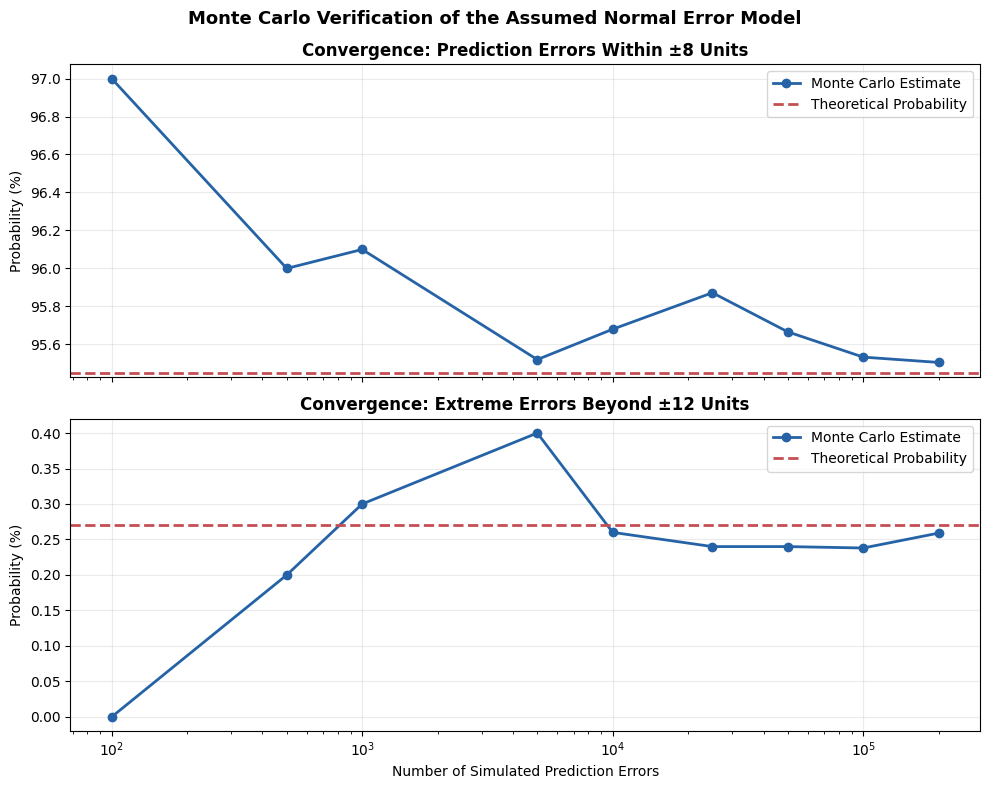


Monte Carlo convergence figure saved.
/content/COM7023_outputs/PROB_Fig02_Monte_Carlo_Convergence.png


In [34]:

# CELL 31: MONTE CARLO CONVERGENCE VISUALISATION

print("GENERATING MONTE CARLO CONVERGENCE FIGURE")
print("=" * 65)

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

# Plot 1: Probability within ±8 units
axes[0].plot(
    sample_sizes,
    convergence_table["P(Within ±8) (%)"],
    marker="o",
    linewidth=2,
    color="#2563a6",
    label="Monte Carlo Estimate"
)

axes[0].axhline(
    theory_central * 100,
    color="#c44e52",
    linestyle="--",
    linewidth=2,
    label="Theoretical Probability"
)

axes[0].set_title(
    "Convergence: Prediction Errors Within ±8 Units",
    fontweight="bold"
)

axes[0].set_ylabel("Probability (%)")
axes[0].grid(alpha=0.25)
axes[0].legend()

# Plot 2: Probability outside ±12 units
axes[1].plot(
    sample_sizes,
    convergence_table["P(Outside ±12) (%)"],
    marker="o",
    linewidth=2,
    color="#2563a6",
    label="Monte Carlo Estimate"
)

axes[1].axhline(
    theory_extreme * 100,
    color="#c44e52",
    linestyle="--",
    linewidth=2,
    label="Theoretical Probability"
)

axes[1].set_title(
    "Convergence: Extreme Errors Beyond ±12 Units",
    fontweight="bold"
)

axes[1].set_xlabel("Number of Simulated Prediction Errors")
axes[1].set_ylabel("Probability (%)")
axes[1].grid(alpha=0.25)
axes[1].legend()

# Logarithmic horizontal axis for sample-size comparison
axes[1].set_xscale("log")

fig.suptitle(
    "Monte Carlo Verification of the Assumed Normal Error Model",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

# Save figure
mc_figure_path = os.path.join(
    output_dir,
    "PROB_Fig02_Monte_Carlo_Convergence.png"
)

fig.savefig(
    mc_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nMonte Carlo convergence figure saved.")
print(mc_figure_path)


In [35]:

# CELL 32: PATIENT GROUP DATA CONSTRUCTION
# COM7023 - TASK 4: STATISTICAL ANALYSIS

print("TASK 4: PATIENT HEALTH RISK GROUP COMPARISON")
print("=" * 65)

# Original data provided in the assessment brief
smoking_data = {
    "Non-smokers": [
        72.4, 74.1, 73.5, 75.2,
        74.8, 73.9, 74.3, 75.0
    ],
    "Moderate smokers": [
        78.6, 79.2, 80.1, 78.9, 79.5,
        80.3, 79.8, 78.7, 79.9, 80.0
    ],
    "Heavy smokers": [
        83.5, 84.2, 85.1,
        83.9, 84.7, 85.3
    ]
}

group_order = [
    "Non-smokers",
    "Moderate smokers",
    "Heavy smokers"
]

# Convert group observations into long-format data
records = []

for group_name, scores in smoking_data.items():
    for observation_number, score in enumerate(scores, 1):
        records.append({
            "Record_ID": f"{group_name[:2]}_{observation_number:02d}",
            "Smoking_Group": group_name,
            "Risk_Score": float(score)
        })

df_risk = pd.DataFrame(records)

# Define ordered categorical grouping
df_risk["Smoking_Group"] = pd.Categorical(
    df_risk["Smoking_Group"],
    categories=group_order,
    ordered=True
)

print("\nOriginal Patient Risk Dataset:")
display(df_risk)

print("\nDataset Shape:", df_risk.shape)
print("Total Observations:", len(df_risk))
print("Number of Groups:", len(group_order))

print("\nVariable Data Types:")
print(df_risk.dtypes)

print("\nDataset construction completed.")


TASK 4: PATIENT HEALTH RISK GROUP COMPARISON

Original Patient Risk Dataset:


,Record_ID,Smoking_Group,Risk_Score
0,No_01,Non-smokers,72.4
1,No_02,Non-smokers,74.1
2,No_03,Non-smokers,73.5
3,No_04,Non-smokers,75.2
4,No_05,Non-smokers,74.8
5,No_06,Non-smokers,73.9
6,No_07,Non-smokers,74.3
7,No_08,Non-smokers,75.0
8,Mo_01,Moderate smokers,78.6
9,Mo_02,Moderate smokers,79.2



Dataset Shape: (24, 3)
Total Observations: 24
Number of Groups: 3

Variable Data Types:
Record_ID          object
Smoking_Group    category
Risk_Score        float64
dtype: object

Dataset construction completed.


In [36]:

# CELL 33: DATA QUALITY AND GROUP-SIZE VERIFICATION

print("DATA QUALITY AND SAMPLE SIZE AUDIT")
print("=" * 65)

# Missing-value summary
missing_summary = df_risk.isna().sum()

print("\nMissing Values:")
display(missing_summary.to_frame("Missing Count"))

# Check numerical validity
assert pd.api.types.is_numeric_dtype(
    df_risk["Risk_Score"]
)

assert np.all(
    np.isfinite(df_risk["Risk_Score"])
)

# Verify sample sizes
expected_counts = {
    "Non-smokers": 8,
    "Moderate smokers": 10,
    "Heavy smokers": 6
}

actual_counts = (
    df_risk.groupby(
        "Smoking_Group",
        observed=True
    )["Risk_Score"]
    .count()
    .reindex(group_order)
)

sample_audit = pd.DataFrame({
    "Expected Sample Size": [
        expected_counts[g] for g in group_order
    ],
    "Actual Sample Size": actual_counts.to_numpy()
}, index=group_order)

sample_audit["Match"] = (
    sample_audit["Expected Sample Size"]
    == sample_audit["Actual Sample Size"]
)

display(sample_audit)

# Confirm the supplied dataset is complete
assert len(df_risk) == 24
assert df_risk["Risk_Score"].isna().sum() == 0
assert sample_audit["Match"].all()
assert df_risk["Record_ID"].is_unique

print("\nMinimum Recorded Score:",
      df_risk["Risk_Score"].min())

print("Maximum Recorded Score:",
      df_risk["Risk_Score"].max())

print("\nUnequal Sample Sizes:",
      actual_counts.nunique() > 1)

print("\nDATA QUALITY VERIFICATION PASSED.")
print("All 24 supplied observations are retained.")


DATA QUALITY AND SAMPLE SIZE AUDIT

Missing Values:


,Missing Count
Record_ID,0
Smoking_Group,0
Risk_Score,0


,Expected Sample Size,Actual Sample Size,Match
Non-smokers,8,8,True
Moderate smokers,10,10,True
Heavy smokers,6,6,True



Minimum Recorded Score: 72.4
Maximum Recorded Score: 85.3

Unequal Sample Sizes: True

DATA QUALITY VERIFICATION PASSED.
All 24 supplied observations are retained.


In [37]:

# CELL 34: COMPREHENSIVE DESCRIPTIVE STATISTICS

from scipy.stats import t as student_t

print("DESCRIPTIVE STATISTICAL ANALYSIS")
print("=" * 65)

# Calculate groupwise descriptive statistics
group_summary = (
    df_risk.groupby(
        "Smoking_Group",
        observed=True
    )["Risk_Score"]
    .agg(
        n="count",
        Mean="mean",
        Median="median",
        SD="std",
        Variance="var",
        Minimum="min",
        Maximum="max"
    )
    .reindex(group_order)
)

# Additional measures of dispersion
group_summary["Range"] = (
    group_summary["Maximum"]
    - group_summary["Minimum"]
)

q1 = df_risk.groupby(
    "Smoking_Group", observed=True
)["Risk_Score"].quantile(0.25)

q3 = df_risk.groupby(
    "Smoking_Group", observed=True
)["Risk_Score"].quantile(0.75)

group_summary["Q1"] = q1
group_summary["Q3"] = q3

group_summary["IQR"] = (
    group_summary["Q3"]
    - group_summary["Q1"]
)

# Standard error of each group mean
group_summary["SEM"] = (
    group_summary["SD"]
    / np.sqrt(group_summary["n"])
)

# 95% confidence intervals for group means
group_summary["T Critical"] = student_t.ppf(
    0.975,
    df=group_summary["n"] - 1
)

group_summary["CI Lower"] = (
    group_summary["Mean"]
    - group_summary["T Critical"]
    * group_summary["SEM"]
)

group_summary["CI Upper"] = (
    group_summary["Mean"]
    + group_summary["T Critical"]
    * group_summary["SEM"]
)

# Table 1: Central tendency and dispersion
print("\nTABLE A: GROUPWISE DESCRIPTIVE STATISTICS")

display(
    group_summary[
        ["n", "Mean", "Median", "SD",
         "Minimum", "Maximum", "IQR"]
    ].round(4)
)

# Table 2: Variability and uncertainty
print("\nTABLE B: VARIABILITY AND MEAN CONFIDENCE INTERVALS")

display(
    group_summary[
        ["Variance", "Range", "SEM",
         "CI Lower", "CI Upper"]
    ].round(4)
)

# Overall summary
print("\nOVERALL DATASET SUMMARY")

print("Total Sample Size:", len(df_risk))
print("Overall Mean:",
      round(df_risk["Risk_Score"].mean(), 4))
print("Overall Sample SD:",
      round(df_risk["Risk_Score"].std(ddof=1), 4))

# Verification
assert group_summary["n"].sum() == 24
assert (group_summary["SD"] > 0).all()
assert (
    group_summary["CI Lower"]
    < group_summary["Mean"]
).all()

assert (
    group_summary["CI Upper"]
    > group_summary["Mean"]
).all()

print("\nDescriptive statistics verification PASSED.")


DESCRIPTIVE STATISTICAL ANALYSIS

TABLE A: GROUPWISE DESCRIPTIVE STATISTICS


,n,Mean,Median,SD,Minimum,Maximum,IQR
Smoking_Group,,,,,,,
Non-smokers,8,74.15,74.20,0.9118,72.4,75.2,1.050
Moderate smokers,10,79.50,79.65,0.6146,78.6,80.3,1.000
Heavy smokers,6,84.45,84.45,0.7036,83.5,85.3,1.025



TABLE B: VARIABILITY AND MEAN CONFIDENCE INTERVALS


,Variance,Range,SEM,CI Lower,CI Upper
Smoking_Group,,,,,
Non-smokers,0.8314,2.8,0.3224,73.3877,74.9123
Moderate smokers,0.3778,1.7,0.1944,79.0603,79.9397
Heavy smokers,0.4950,1.8,0.2872,83.7117,85.1883



OVERALL DATASET SUMMARY
Total Sample Size: 24
Overall Mean: 78.9542
Overall Sample SD: 4.0676

Descriptive statistics verification PASSED.


GENERATING GROUPWISE RISK SCORE VISUALISATION


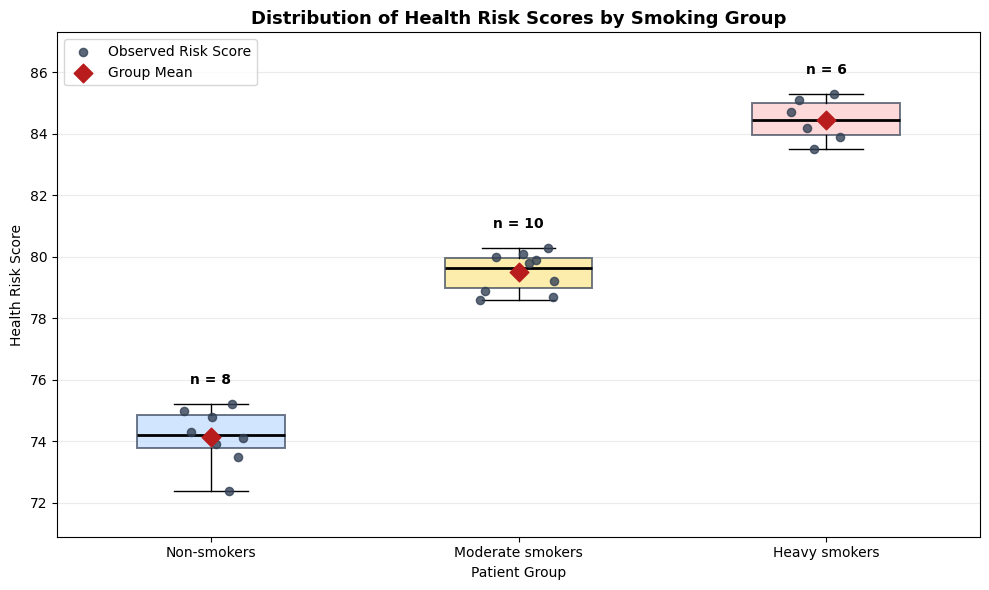


Group distribution figure saved successfully.
/content/COM7023_outputs/STAT_Fig01_Group_Risk_Distribution.png


In [38]:

# CELL 35: GROUPWISE RISK DISTRIBUTION VISUALISATION

import os

print("GENERATING GROUPWISE RISK SCORE VISUALISATION")
print("=" * 65)

# Prepare original observations by group
group_arrays = [
    np.array(smoking_data[g], dtype=float)
    for g in group_order
]

positions = np.arange(1, len(group_order) + 1)

# Reproducible horizontal jitter
plot_rng = np.random.default_rng(7023)

fig, ax = plt.subplots(figsize=(10, 6))

# Boxplots of observed distributions
box = ax.boxplot(
    group_arrays,
    positions=positions,
    widths=0.48,
    patch_artist=True,
    showfliers=False,
    medianprops={
        "color": "black",
        "linewidth": 2
    },
    boxprops={
        "edgecolor": "#334155",
        "linewidth": 1.4
    }
)

box_colours = [
    "#bfdbfe",
    "#fde68a",
    "#fecaca"
]

for patch, colour in zip(
    box["boxes"], box_colours
):
    patch.set_facecolor(colour)
    patch.set_alpha(0.7)

# Individual observations and group means
for index, values in enumerate(group_arrays):

    position = positions[index]

    jitter = plot_rng.uniform(
        -0.13, 0.13, size=len(values)
    )

    ax.scatter(
        np.full(len(values), position) + jitter,
        values,
        color="#334155",
        alpha=0.8,
        s=35,
        zorder=4,
        label="Observed Risk Score" if index == 0 else None
    )

    group_mean = np.mean(values)

    ax.scatter(
        position,
        group_mean,
        marker="D",
        color="#b91c1c",
        s=90,
        zorder=5,
        label="Group Mean" if index == 0 else None
    )

    ax.text(
        position,
        np.max(values) + 0.65,
        f"n = {len(values)}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticks(positions)
ax.set_xticklabels(group_order)

ax.set_title(
    "Distribution of Health Risk Scores by Smoking Group",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Patient Group")
ax.set_ylabel("Health Risk Score")

ax.set_ylim(
    df_risk["Risk_Score"].min() - 1.5,
    df_risk["Risk_Score"].max() + 2
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(loc="upper left")

plt.tight_layout()

# Export high-resolution figure
output_dir = "/content/COM7023_outputs"
os.makedirs(output_dir, exist_ok=True)

statistics_figure_path = os.path.join(
    output_dir,
    "STAT_Fig01_Group_Risk_Distribution.png"
)

fig.savefig(
    statistics_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nGroup distribution figure saved successfully.")
print(statistics_figure_path)


In [39]:

# CELL 36: NORMALITY ASSUMPTION DIAGNOSTICS

from scipy import stats as scipy_stats

print("TASK 4B: NORMALITY ASSUMPTION ANALYSIS")
print("=" * 65)

alpha = 0.05

# Prepare groups for statistical testing
stat_groups = {
    group: np.array(smoking_data[group], dtype=float)
    for group in group_order
}

normality_results = []

for group_name, values in stat_groups.items():

    # Shapiro-Wilk normality test
    W_stat, p_value = scipy_stats.shapiro(values)

    normality_results.append({
        "Patient Group": group_name,
        "Sample Size": len(values),
        "Shapiro W": W_stat,
        "P-value": p_value,
        "Decision at 0.05": (
            "Reject normality"
            if p_value < alpha
            else "No evidence to reject normality"
        )
    })

normality_table = pd.DataFrame(normality_results)

print("\nGROUPWISE SHAPIRO-WILK RESULTS")
display(normality_table.round(6))

# Construct group-centred residuals
group_residuals = []

for group_name, values in stat_groups.items():

    group_mean = np.mean(values)
    residuals = values - group_mean

    group_residuals.extend(residuals)

group_residuals = np.array(
    group_residuals, dtype=float
)

# Shapiro-Wilk test on pooled residuals
residual_W, residual_p = scipy_stats.shapiro(
    group_residuals
)

print("\nGROUP-CENTRED RESIDUAL NORMALITY")

print("Shapiro-Wilk W:", round(residual_W, 6))
print("P-value:", round(residual_p, 6))

print("\nNumber of residuals:", len(group_residuals))
print("Residual Mean:", np.mean(group_residuals))

assert len(group_residuals) == len(df_risk)
assert np.isclose(np.mean(group_residuals), 0)

print("\nNormality diagnostics completed.")
print("Note: Small samples reduce the power of normality tests.")


TASK 4B: NORMALITY ASSUMPTION ANALYSIS

GROUPWISE SHAPIRO-WILK RESULTS


,Patient Group,Sample Size,Shapiro W,P-value,Decision at 0.05
0,Non-smokers,8,0.938832,0.599623,No evidence to reject normality
1,Moderate smokers,10,0.921063,0.365909,No evidence to reject normality
2,Heavy smokers,6,0.956144,0.789588,No evidence to reject normality



GROUP-CENTRED RESIDUAL NORMALITY
Shapiro-Wilk W: 0.95549
P-value: 0.354648

Number of residuals: 24
Residual Mean: -2.3684757858670005e-15

Normality diagnostics completed.
Note: Small samples reduce the power of normality tests.


GENERATING NORMALITY DIAGNOSTIC PLOTS


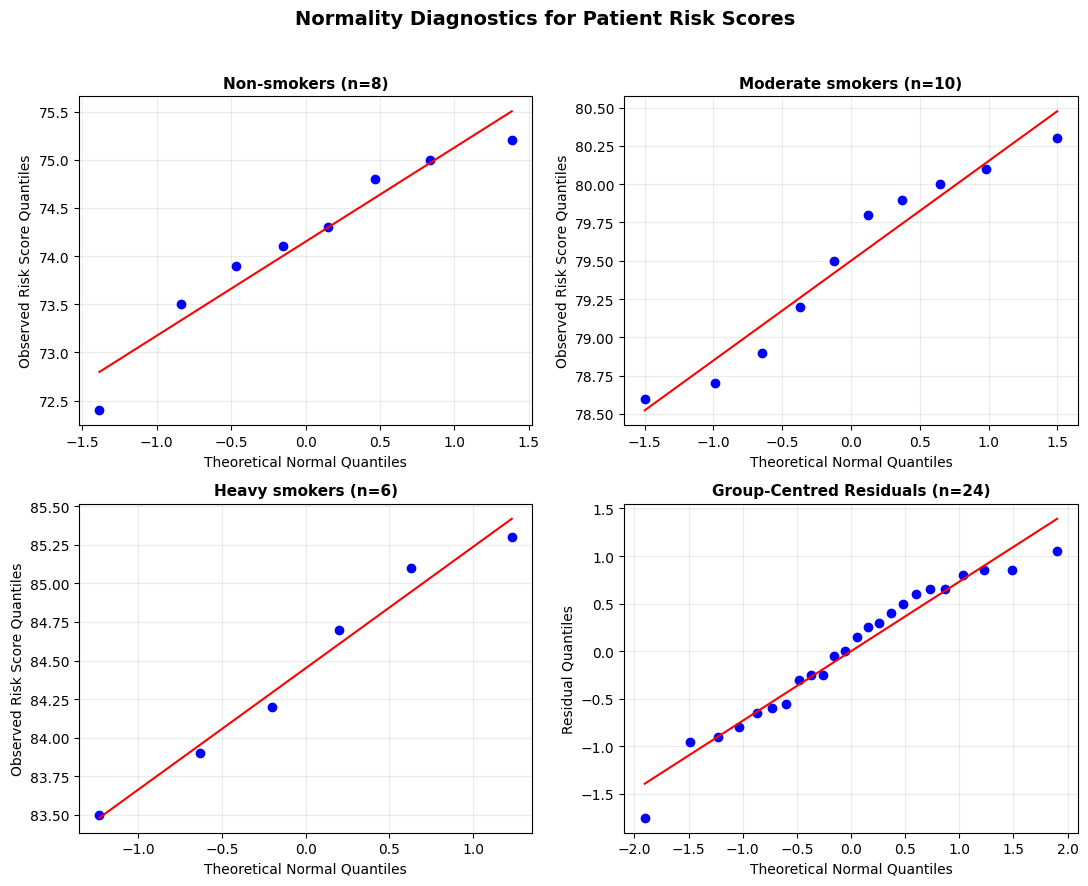


Q-Q diagnostic plots saved.
/content/COM7023_outputs/STAT_Fig02_Normality_QQ_Plots.png


In [40]:

# CELL 37: NORMAL Q-Q PLOT DIAGNOSTICS

print("GENERATING NORMALITY DIAGNOSTIC PLOTS")
print("=" * 65)

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 9)
)

axes = axes.flatten()

# Q-Q plots for each patient group
for i, group_name in enumerate(group_order):

    values = stat_groups[group_name]

    scipy_stats.probplot(
        values,
        dist="norm",
        plot=axes[i]
    )

    axes[i].set_title(
        f"{group_name} (n={len(values)})",
        fontsize=11,
        fontweight="bold"
    )

    axes[i].set_xlabel("Theoretical Normal Quantiles")
    axes[i].set_ylabel("Observed Risk Score Quantiles")
    axes[i].grid(alpha=0.25)

# Q-Q plot for group-centred residuals
scipy_stats.probplot(
    group_residuals,
    dist="norm",
    plot=axes[3]
)

axes[3].set_title(
    "Group-Centred Residuals (n=24)",
    fontsize=11,
    fontweight="bold"
)

axes[3].set_xlabel("Theoretical Normal Quantiles")
axes[3].set_ylabel("Residual Quantiles")
axes[3].grid(alpha=0.25)

fig.suptitle(
    "Normality Diagnostics for Patient Risk Scores",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save diagnostic figure
qq_plot_path = os.path.join(
    output_dir,
    "STAT_Fig02_Normality_QQ_Plots.png"
)

fig.savefig(
    qq_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nQ-Q diagnostic plots saved.")
print(qq_plot_path)


In [41]:

# CELL 38: HOMOGENEITY OF VARIANCE DIAGNOSTICS

print("VARIANCE HOMOGENEITY INVESTIGATION")
print("=" * 65)

values_list = [
    stat_groups[group]
    for group in group_order
]

# Classical Levene test (mean-centred)
levene_mean = scipy_stats.levene(
    *values_list,
    center="mean"
)

# Brown-Forsythe variation (median-centred)
brown_forsythe = scipy_stats.levene(
    *values_list,
    center="median"
)

# Fligner-Killeen test
fligner_result = scipy_stats.fligner(
    *values_list
)

# Sample variance comparison
group_variances = [
    np.var(values, ddof=1)
    for values in values_list
]

variance_ratio = (
    max(group_variances) / min(group_variances)
)

# Create test summary
variance_tests = pd.DataFrame({
    "Test": [
        "Levene (Mean-centred)",
        "Brown-Forsythe (Median-centred)",
        "Fligner-Killeen"
    ],
    "Statistic": [
        levene_mean.statistic,
        brown_forsythe.statistic,
        fligner_result.statistic
    ],
    "P-value": [
        levene_mean.pvalue,
        brown_forsythe.pvalue,
        fligner_result.pvalue
    ]
})

variance_tests["Decision at 0.05"] = (
    variance_tests["P-value"].apply(
        lambda p: (
            "Evidence of unequal variances"
            if p < alpha
            else "Insufficient evidence of unequal variances"
        )
    )
)

print("\nHOMOGENEITY TEST RESULTS")
display(variance_tests.round(6))

# Detailed variance summary
variance_details = pd.DataFrame({
    "Patient Group": group_order,
    "Sample Size": [
        len(values) for values in values_list
    ],
    "Sample Variance": group_variances,
    "Sample SD": [
        np.std(values, ddof=1)
        for values in values_list
    ]
})

print("\nGROUPWISE VARIABILITY")
display(variance_details.round(6))

print("\nMaximum / Minimum Variance Ratio:",
      round(variance_ratio, 6))

print("\nVariance diagnostics completed.")
print(
    "Non-significant tests do not prove "
    "that population variances are equal."
)


VARIANCE HOMOGENEITY INVESTIGATION

HOMOGENEITY TEST RESULTS


,Test,Statistic,P-value,Decision at 0.05
0,Levene (Mean-centred),0.339743,0.715794,Insufficient evidence of unequal variances
1,Brown-Forsythe (Median-centred),0.316292,0.732259,Insufficient evidence of unequal variances
2,Fligner-Killeen,0.323521,0.850645,Insufficient evidence of unequal variances



GROUPWISE VARIABILITY


,Patient Group,Sample Size,Sample Variance,Sample SD
0,Non-smokers,8,0.831429,0.911827
1,Moderate smokers,10,0.377778,0.614636
2,Heavy smokers,6,0.495000,0.703562



Maximum / Minimum Variance Ratio: 2.20084

Variance diagnostics completed.
Non-significant tests do not prove that population variances are equal.


In [42]:

# CELL 39: OUTLIER SCREENING AND ASSUMPTION AUDIT

print("OUTLIER SCREENING AND ASSUMPTION REVIEW")
print("=" * 65)

outlier_records = []

for group_name, values in stat_groups.items():

    # Quartiles using linear interpolation
    q1 = np.quantile(values, 0.25)
    q3 = np.quantile(values, 0.75)

    iqr = q3 - q1

    # Tukey's 1.5*IQR fences
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    # Flag potential observations outside fences
    outliers = values[
        (values < lower_fence)
        | (values > upper_fence)
    ]

    outlier_records.append({
        "Patient Group": group_name,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Fence": lower_fence,
        "Upper Fence": upper_fence,
        "Outlier Count": len(outliers),
        "Flagged Values": (
            ", ".join(map(str, outliers))
            if len(outliers) > 0
            else "None"
        )
    })

outlier_table = pd.DataFrame(outlier_records)

print("\nGROUPWISE OUTLIER SCREENING")
display(outlier_table.round(5))

# Summarise statistical assumptions
group_normality_alerts = int(
    (normality_table["P-value"] < alpha).sum()
)

variance_alert = bool(
    brown_forsythe.pvalue < alpha
)

outlier_count = int(
    outlier_table["Outlier Count"].sum()
)

assumption_summary = pd.DataFrame({
    "Assumption": [
        "Normality",
        "Variance Homogeneity",
        "Potential Outliers",
        "Observation Independence",
        "Unequal Sample Sizes"
    ],
    "Finding": [
        (
            f"{group_normality_alerts} of 3 groups "
            "flagged by Shapiro-Wilk"
        ),
        (
            "Brown-Forsythe flagged variance differences"
            if variance_alert
            else "No variance difference detected by Brown-Forsythe"
        ),
        f"{outlier_count} observations flagged by IQR rule",
        "Cannot be confirmed from supplied dataset",
        "Present: n = 8, 10 and 6"
    ],
    "Interpretation": [
        "Assess with Q-Q plots and small-sample caution",
        "Compare conventional and Welch ANOVA",
        "Inspect any flagged observations; do not automatically delete",
        "Requires information about sampling and repeated measurements",
        "Use methods that accommodate unequal group sizes"
    ]
})

print("\nCOMBINED ASSUMPTION AUDIT")
display(assumption_summary)

print("\nSTATISTICAL ASSUMPTION DIAGNOSTICS COMPLETED")

print("\nNEXT STAGE:")
print("Conventional ANOVA, Welch ANOVA,")
print("effect sizes and appropriate post-hoc comparisons.")


OUTLIER SCREENING AND ASSUMPTION REVIEW

GROUPWISE OUTLIER SCREENING


,Patient Group,Q1,Q3,IQR,Lower Fence,Upper Fence,Outlier Count,Flagged Values
0,Non-smokers,73.800,74.850,1.050,72.2250,76.4250,0,None
1,Moderate smokers,78.975,79.975,1.000,77.4750,81.4750,0,None
2,Heavy smokers,83.975,85.000,1.025,82.4375,86.5375,0,None



COMBINED ASSUMPTION AUDIT


,Assumption,Finding,Interpretation
0,Normality,0 of 3 groups flagged by Shapiro-Wilk,Assess with Q-Q plots and small-sample caution
1,Variance Homogeneity,No variance difference detected by Brown-Forsythe,Compare conventional and Welch ANOVA
2,Potential Outliers,0 observations flagged by IQR rule,Inspect any flagged observations; do not autom...
3,Observation Independence,Cannot be confirmed from supplied dataset,Requires information about sampling and repeat...
4,Unequal Sample Sizes,"Present: n = 8, 10 and 6",Use methods that accommodate unequal group sizes



STATISTICAL ASSUMPTION DIAGNOSTICS COMPLETED

NEXT STAGE:
Conventional ANOVA, Welch ANOVA,
effect sizes and appropriate post-hoc comparisons.


In [43]:

# CELL 40: ONE-WAY ANOVA
# Manual decomposition and independent SciPy verification

print("ONE-WAY ANALYSIS OF VARIANCE")
print("=" * 65)

# Significance level
alpha = 0.05

# Hypotheses
print("H0: All three population mean risk scores are equal.")
print("H1: At least one population mean differs.")

# Total observations and number of groups
N = sum(len(group) for group in values_list)
k = len(values_list)

all_scores = np.concatenate(values_list)
grand_mean = np.mean(all_scores)

# Between-group sum of squares
SS_between = sum(
    len(group) * (np.mean(group) - grand_mean)**2
    for group in values_list
)

# Within-group sum of squares
SS_within = sum(
    np.sum((group - np.mean(group))**2)
    for group in values_list
)

SS_total = np.sum(
    (all_scores - grand_mean)**2
)

# Degrees of freedom
df_between = k - 1
df_within = N - k
df_total = N - 1

# Mean squares and F-statistic
MS_between = SS_between / df_between
MS_within = SS_within / df_within

F_manual = MS_between / MS_within
p_manual = scipy_stats.f.sf(
    F_manual, df_between, df_within
)

# Independent SciPy verification
F_scipy, p_scipy = scipy_stats.f_oneway(
    *values_list
)

# ANOVA summary table
anova_table = pd.DataFrame({
    "Source": ["Between Groups", "Within Groups", "Total"],
    "Sum of Squares": [
        SS_between, SS_within, SS_total
    ],
    "df": [df_between, df_within, df_total],
    "Mean Square": [MS_between, MS_within, np.nan],
    "F": [F_manual, np.nan, np.nan],
    "P-value": [p_manual, np.nan, np.nan]
})

display(anova_table)

# Validate decomposition and numerical results
np.testing.assert_allclose(
    SS_between + SS_within,
    SS_total,
    rtol=1e-12
)

np.testing.assert_allclose(
    [F_manual, p_manual],
    [F_scipy, p_scipy],
    rtol=1e-10,
    atol=1e-14
)

print(f"\nManual F-statistic: {F_manual:.6f}")
print(f"SciPy F-statistic: {F_scipy:.6f}")
print(f"P-value: {p_scipy:.12e}")

print("\nDecision:",
      "Reject H0" if p_scipy < alpha else "Do not reject H0")

print("\nManual and SciPy ANOVA verification PASSED.")


ONE-WAY ANALYSIS OF VARIANCE
H0: All three population mean risk scores are equal.
H1: At least one population mean differs.


,Source,Sum of Squares,df,Mean Square,F,P-value
0,Between Groups,368.844583,2,184.422292,331.155889,1.317662e-16
1,Within Groups,11.695000,21,0.556905,NaN,NaN
2,Total,380.539583,23,NaN,NaN,NaN



Manual F-statistic: 331.155889
SciPy F-statistic: 331.155889
P-value: 1.317662153713e-16

Decision: Reject H0

Manual and SciPy ANOVA verification PASSED.


In [44]:

# CELL 41: WELCH ANOVA AND INDEPENDENT VERIFICATION

print("WELCH ANOVA - ROBUSTNESS ANALYSIS")
print("=" * 65)

# Sample size, mean and variance for each group
n_i = np.array([len(g) for g in values_list], float)
mean_i = np.array([np.mean(g) for g in values_list])
var_i = np.array([np.var(g, ddof=1) for g in values_list])

# Inverse-variance weights
weights = n_i / var_i
total_weight = np.sum(weights)

# Weighted grand mean
weighted_mean = np.sum(weights * mean_i) / total_weight

# Welch correction factor
lambda_term = np.sum(
    ((1 - weights / total_weight)**2) / (n_i - 1)
)

correction = (
    1 + (2 * (k - 2) / (k**2 - 1)) * lambda_term
)

# Welch F-statistic and degrees of freedom
F_welch_manual = (
    np.sum(weights * (mean_i - weighted_mean)**2)
    / (k - 1)
) / correction

df_welch_1 = k - 1
df_welch_2 = (k**2 - 1) / (3 * lambda_term)

p_welch_manual = scipy_stats.f.sf(
    F_welch_manual,
    df_welch_1,
    df_welch_2
)

# Independent SciPy calculation (SciPy 1.15+)
welch_result = scipy_stats.f_oneway(
    *values_list,
    equal_var=False
)

# Compare the methods
np.testing.assert_allclose(
    [F_welch_manual, p_welch_manual],
    [welch_result.statistic, welch_result.pvalue],
    rtol=1e-10
)

welch_summary = pd.DataFrame({
    "Metric": [
        "Welch F-statistic",
        "Numerator df",
        "Denominator df",
        "P-value",
        "Weighted Grand Mean"
    ],
    "Value": [
        F_welch_manual,
        df_welch_1,
        df_welch_2,
        p_welch_manual,
        weighted_mean
    ]
})

display(welch_summary)

print(f"\nWelch F: {F_welch_manual:.6f}")
print(f"Welch p-value: {p_welch_manual:.12e}")

print("\nComparison with Conventional ANOVA:")
print(f"Conventional F: {F_scipy:.6f}")
print(f"Conventional p: {p_scipy:.12e}")

print("\nWelch decision:",
      "Reject H0" if p_welch_manual < alpha
      else "Do not reject H0")

print("\nWelch ANOVA verification PASSED.")


WELCH ANOVA - ROBUSTNESS ANALYSIS


,Metric,Value
0,Welch F-statistic,2.701711e+02
1,Numerator df,2.000000e+00
2,Denominator df,1.178880e+01
3,P-value,1.422251e-10
4,Weighted Grand Mean,7.967676e+01



Welch F: 270.171133
Welch p-value: 1.422250663474e-10

Comparison with Conventional ANOVA:
Conventional F: 331.155889
Conventional p: 1.317662153713e-16

Welch decision: Reject H0

Welch ANOVA verification PASSED.


In [45]:

# CELL 42: ANOVA EFFECT SIZE ANALYSIS

print("STATISTICAL EFFECT SIZE INVESTIGATION")
print("=" * 65)

# Eta squared: proportion of observed variance
# explained by group membership in this sample
eta_squared = SS_between / SS_total

# Omega squared: bias-adjusted effect-size estimate
omega_squared = (
    SS_between - df_between * MS_within
) / (
    SS_total + MS_within
)

# Epsilon squared
epsilon_squared = (
    SS_between - df_between * MS_within
) / SS_total

# Cohen's f derived from eta squared
cohens_f = np.sqrt(
    eta_squared / (1 - eta_squared)
)

effect_size_table = pd.DataFrame({
    "Measure": [
        "Eta Squared",
        "Omega Squared",
        "Epsilon Squared",
        "Cohen's f"
    ],
    "Estimate": [
        eta_squared,
        omega_squared,
        epsilon_squared,
        cohens_f
    ]
})

display(effect_size_table.round(6))

print("\nBetween-group variation (% of observed total):",
      f"{eta_squared * 100:.4f}%")

print("Within-group variation (% of observed total):",
      f"{(1 - eta_squared) * 100:.4f}%")

# Consistency checks
assert 0 <= eta_squared <= 1
assert np.isfinite(omega_squared)
assert np.isfinite(epsilon_squared)

print("\nEffect size calculations completed.")

print(
    "These measures describe the supplied sample; "
    "they do not establish causation."
)


STATISTICAL EFFECT SIZE INVESTIGATION


,Measure,Estimate
0,Eta Squared,0.969267
1,Omega Squared,0.964928
2,Epsilon Squared,0.966340
3,Cohen's f,5.615929



Between-group variation (% of observed total): 96.9267%
Within-group variation (% of observed total): 3.0733%

Effect size calculations completed.
These measures describe the supplied sample; they do not establish causation.


In [46]:

# CELL 43: TUKEY-KRAMER POST-HOC COMPARISONS

print("POST-HOC PAIRWISE COMPARISONS")
print("=" * 65)

# SciPy Tukey HSD accommodates unequal group sizes
# through the Tukey-Kramer approach
tukey_result = scipy_stats.tukey_hsd(
    *values_list
)

# Simultaneous 95% confidence intervals
tukey_ci = tukey_result.confidence_interval(
    confidence_level=0.95
)

pairwise_records = []

# Three unique pairwise comparisons
for i in range(k):
    for j in range(i + 1, k):

        mean_difference = (
            np.mean(values_list[i])
            - np.mean(values_list[j])
        )

        p_value = float(tukey_result.pvalue[i, j])

        lower_ci = float(tukey_ci.low[i, j])
        upper_ci = float(tukey_ci.high[i, j])

        pairwise_records.append({
            "Group 1": group_order[i],
            "Group 2": group_order[j],
            "Mean Difference (G1-G2)": mean_difference,
            "95% CI Lower": lower_ci,
            "95% CI Upper": upper_ci,
            "P-value": (
                "<0.001" if p_value < 0.001
                else f"{p_value:.6f}"
            ),
            "Significant": p_value < alpha
        })

posthoc_table = pd.DataFrame(
    pairwise_records
)

display(posthoc_table.round(6))

# Check all three unique pairs were evaluated
assert len(posthoc_table) == 3

# Validate pairwise mean differences
for i in range(k):
    for j in range(i + 1, k):
        np.testing.assert_allclose(
            tukey_result.statistic[i, j],
            np.mean(values_list[i]) - np.mean(values_list[j]),
            atol=1e-10
        )

print("\nNumber of comparisons:",
      len(posthoc_table))

print("Significant pairwise comparisons:",
      int(posthoc_table["Significant"].sum()))

print("\nTukey-Kramer post-hoc analysis completed.")
print("P-values displayed as <0.001 are not zero.")


POST-HOC PAIRWISE COMPARISONS


,Group 1,Group 2,Mean Difference (G1-G2),95% CI Lower,95% CI Upper,P-value,Significant
0,Non-smokers,Moderate smokers,-5.35,-6.242238,-4.457762,<0.001,True
1,Non-smokers,Heavy smokers,-10.30,-11.315857,-9.284143,<0.001,True
2,Moderate smokers,Heavy smokers,-4.95,-5.921345,-3.978655,<0.001,True



Number of comparisons: 3
Significant pairwise comparisons: 3

Tukey-Kramer post-hoc analysis completed.
P-values displayed as <0.001 are not zero.


In [47]:

# CELL 44: GAMES-HOWELL ROBUST POST-HOC ANALYSIS

print("GAMES-HOWELL PAIRWISE COMPARISONS")
print("=" * 65)

from itertools import combinations
from scipy.stats import studentized_range

gh_records = []

for i, j in combinations(range(k), 2):

    # Mean difference: Group i minus Group j
    difference = mean_i[i] - mean_i[j]

    # Variance contributions
    vi = var_i[i] / n_i[i]
    vj = var_i[j] / n_i[j]

    # Standard error for the mean difference
    se_difference = np.sqrt(vi + vj)

    # Welch-Satterthwaite degrees of freedom
    df_pair = (
        (vi + vj)**2
        / (
            vi**2 / (n_i[i] - 1)
            + vj**2 / (n_i[j] - 1)
        )
    )

    # Games-Howell studentized-range statistic
    q_statistic = (
        np.abs(difference)
        / np.sqrt((vi + vj) / 2)
    )

    # Multiplicity-adjusted p-value
    p_adjusted = studentized_range.sf(
        q_statistic, k, df_pair
    )

    # Simultaneous 95% confidence interval
    q_critical = studentized_range.ppf(
        1 - alpha, k, df_pair
    )

    margin = (
        q_critical
        * np.sqrt((vi + vj) / 2)
    )

    gh_records.append({
        "Group 1": group_order[i],
        "Group 2": group_order[j],
        "Mean Difference": difference,
        "SE Difference": se_difference,
        "Welch df": df_pair,
        "GH q-statistic": q_statistic,
        "Adjusted P-value": p_adjusted,
        "95% CI Lower": difference - margin,
        "95% CI Upper": difference + margin,
        "Significant": p_adjusted < alpha
    })

gh_table = pd.DataFrame(gh_records)

display(gh_table.round(6))

# Check confidence intervals and pairwise results
assert len(gh_table) == 3
assert (gh_table["95% CI Lower"]
        <= gh_table["Mean Difference"]).all()
assert (gh_table["95% CI Upper"]
        >= gh_table["Mean Difference"]).all()

print("\nGames-Howell analysis completed.")

print("Significant comparisons:",
      int(gh_table["Significant"].sum()), "of 3")

print(
    "\nNote: This is a robustness comparison "
    "allowing unequal group variances."
)


GAMES-HOWELL PAIRWISE COMPARISONS


,Group 1,Group 2,Mean Difference,SE Difference,Welch df,GH q-statistic,Adjusted P-value,95% CI Lower,95% CI Upper,Significant
0,Non-smokers,Moderate smokers,-5.35,0.376439,11.801101,20.098985,0.0,-6.356573,-4.343427,True
1,Non-smokers,Heavy smokers,-10.30,0.431774,11.967069,33.736186,0.0,-11.452341,-9.147659,True
2,Moderate smokers,Heavy smokers,-4.95,0.346811,9.518701,20.184942,0.0,-5.908653,-3.991347,True



Games-Howell analysis completed.
Significant comparisons: 3 of 3

Note: This is a robustness comparison allowing unequal group variances.


GENERATING POST-HOC COMPARISON FIGURE


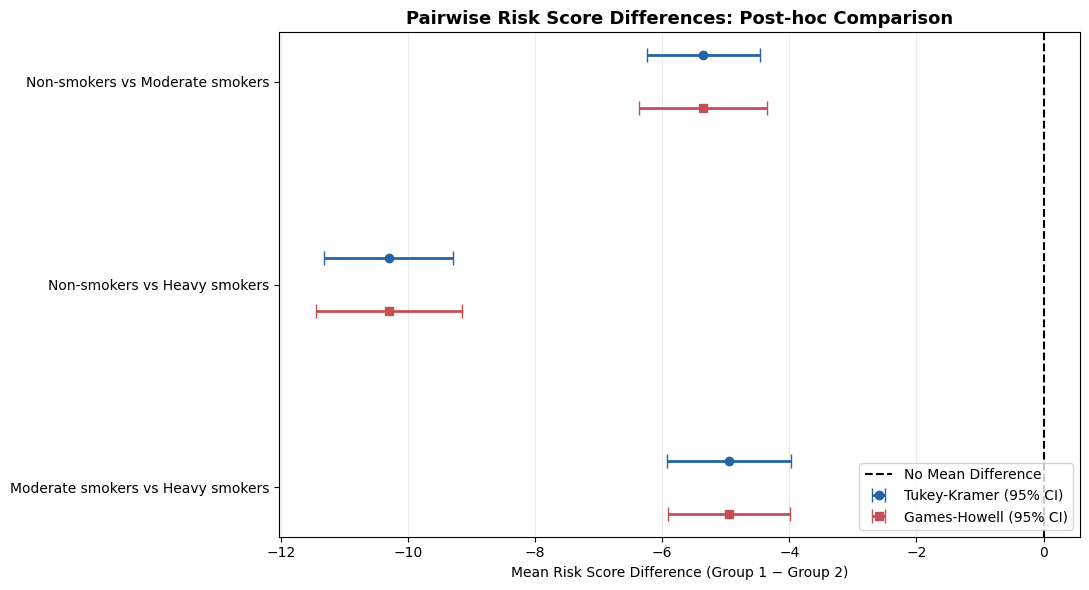


Post-hoc comparison figure saved.
/content/COM7023_outputs/STAT_Fig03_Posthoc_Comparison.png


In [48]:

# CELL 45: PAIRWISE DIFFERENCE FOREST PLOT

print("GENERATING POST-HOC COMPARISON FIGURE")
print("=" * 65)

comparison_labels = [
    f"{row['Group 1']} vs {row['Group 2']}"
    for _, row in gh_table.iterrows()
]

positions = np.arange(len(comparison_labels))

fig, ax = plt.subplots(figsize=(11, 6))

# Extract Tukey-Kramer results
tukey_estimates = posthoc_table[
    "Mean Difference (G1-G2)"
].to_numpy(dtype=float)

tukey_lower = posthoc_table[
    "95% CI Lower"
].to_numpy(dtype=float)

tukey_upper = posthoc_table[
    "95% CI Upper"
].to_numpy(dtype=float)

# Extract Games-Howell results
gh_estimates = gh_table[
    "Mean Difference"
].to_numpy(dtype=float)

gh_lower = gh_table[
    "95% CI Lower"
].to_numpy(dtype=float)

gh_upper = gh_table[
    "95% CI Upper"
].to_numpy(dtype=float)

# Tukey-Kramer confidence intervals
ax.errorbar(
    tukey_estimates,
    positions - 0.13,
    xerr=[
        tukey_estimates - tukey_lower,
        tukey_upper - tukey_estimates
    ],
    fmt="o",
    capsize=5,
    linewidth=2,
    color="#2563a6",
    label="Tukey-Kramer (95% CI)"
)

# Games-Howell confidence intervals
ax.errorbar(
    gh_estimates,
    positions + 0.13,
    xerr=[
        gh_estimates - gh_lower,
        gh_upper - gh_estimates
    ],
    fmt="s",
    capsize=5,
    linewidth=2,
    color="#c44e52",
    label="Games-Howell (95% CI)"
)

# Zero difference reference
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="No Mean Difference"
)

ax.set_yticks(positions)
ax.set_yticklabels(comparison_labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Mean Risk Score Difference (Group 1 − Group 2)"
)

ax.set_title(
    "Pairwise Risk Score Differences: Post-hoc Comparison",
    fontsize=13,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()

# Export figure
posthoc_path = os.path.join(
    output_dir,
    "STAT_Fig03_Posthoc_Comparison.png"
)

fig.savefig(
    posthoc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nPost-hoc comparison figure saved.")
print(posthoc_path)


In [49]:

# CELL 46: FINAL STATISTICAL QUALITY ASSURANCE

print("FINAL STATISTICAL VALIDATION REPORT")
print("=" * 65)

# Independent consistency checks
validation_checks = {
    "Total observations equal 24":
        N == 24,

    "Three patient groups retained":
        k == 3,

    "Unequal group sizes preserved":
        list(n_i.astype(int)) == [8, 10, 6],

    "ANOVA sums of squares consistent":
        np.isclose(
            SS_between + SS_within,
            SS_total
        ),

    "Manual and SciPy ANOVA agree":
        np.isclose(F_manual, F_scipy),

    "Welch ANOVA significance verified":
        p_welch_manual < alpha,

    "Classical ANOVA significance verified":
        p_scipy < alpha,

    "Effect size within valid range":
        0 <= eta_squared <= 1,

    "Three Tukey comparisons completed":
        len(posthoc_table) == 3,

    "Three Games-Howell comparisons completed":
        len(gh_table) == 3,

    "All risk scores are finite":
        np.isfinite(all_scores).all()
}

validation_table = pd.DataFrame({
    "Verification": list(validation_checks.keys()),
    "Passed": list(validation_checks.values())
})

display(validation_table)

assert all(validation_checks.values())

# Compact final numerical summary
final_stat_summary = pd.DataFrame({
    "Statistic": [
        "Total Sample Size",
        "Number of Groups",
        "Conventional ANOVA F",
        "Conventional ANOVA p",
        "Welch ANOVA F",
        "Welch ANOVA p",
        "Eta Squared",
        "Omega Squared",
        "Tukey Significant Pairs",
        "Games-Howell Significant Pairs"
    ],
    "Value": [
        N,
        k,
        F_scipy,
        p_scipy,
        F_welch_manual,
        p_welch_manual,
        eta_squared,
        omega_squared,
        int(posthoc_table["Significant"].sum()),
        int(gh_table["Significant"].sum())
    ]
})

print("\nFINAL STATISTICAL RESULTS")
display(final_stat_summary)

# Export reproducible result tables
export_tables = {
    "Group_Descriptive_Statistics.csv": group_summary,
    "ANOVA_Results.csv": anova_table,
    "Welch_ANOVA_Results.csv": welch_summary,
    "Effect_Sizes.csv": effect_size_table,
    "Tukey_Posthoc.csv": posthoc_table,
    "Games_Howell_Posthoc.csv": gh_table,
    "Final_Statistical_Summary.csv": final_stat_summary
}

for filename, table in export_tables.items():
    destination = os.path.join(output_dir, filename)
    table.to_csv(destination, index=False)

print("\nAll statistical quality checks PASSED.")
print("Result tables exported to:", output_dir)

print("\nLIMITATION:")
print(
    "Independence and clinical validity cannot be "
    "established from the supplied observations alone."
)


FINAL STATISTICAL VALIDATION REPORT


,Verification,Passed
0,Total observations equal 24,True
1,Three patient groups retained,True
2,Unequal group sizes preserved,True
3,ANOVA sums of squares consistent,True
4,Manual and SciPy ANOVA agree,True
5,Welch ANOVA significance verified,True
6,Classical ANOVA significance verified,True
7,Effect size within valid range,True
8,Three Tukey comparisons completed,True
9,Three Games-Howell comparisons completed,True



FINAL STATISTICAL RESULTS


,Statistic,Value
0,Total Sample Size,2.400000e+01
1,Number of Groups,3.000000e+00
2,Conventional ANOVA F,3.311559e+02
3,Conventional ANOVA p,1.317662e-16
4,Welch ANOVA F,2.701711e+02
5,Welch ANOVA p,1.422251e-10
6,Eta Squared,9.692673e-01
7,Omega Squared,9.649283e-01
8,Tukey Significant Pairs,3.000000e+00
9,Games-Howell Significant Pairs,3.000000e+00



All statistical quality checks PASSED.
Result tables exported to: /content/COM7023_outputs

LIMITATION:
Independence and clinical validity cannot be established from the supplied observations alone.


In [50]:

# CELL 47: FINAL RESULTS EXPORT CORRECTION

print("FINAL EXPORT QUALITY CHECK")
print("=" * 60)

# Preserve smoking-group names in the exported table
descriptive_export = group_summary.reset_index()

descriptive_export.to_csv(
    os.path.join(
        output_dir,
        "Group_Descriptive_Statistics.csv"
    ),
    index=False
)

# Preserve full numerical p-values
gh_table.to_csv(
    os.path.join(
        output_dir,
        "Games_Howell_Posthoc.csv"
    ),
    index=False,
    float_format="%.12g"
)

# Display publication-friendly p-values
gh_display = gh_table[
    [
        "Group 1", "Group 2",
        "Mean Difference",
        "Adjusted P-value",
        "95% CI Lower", "95% CI Upper"
    ]
].copy()

gh_display["Adjusted P-value"] = (
    gh_display["Adjusted P-value"]
    .map(lambda p: f"{p:.3e}")
)

display(gh_display)

# Verify smoking-group labels are preserved
assert "Smoking_Group" in descriptive_export.columns
assert len(descriptive_export) == 3

print("\nCorrected CSV exports successfully.")
print("All final export checks PASSED.")


FINAL EXPORT QUALITY CHECK


,Group 1,Group 2,Mean Difference,Adjusted P-value,95% CI Lower,95% CI Upper
0,Non-smokers,Moderate smokers,-5.35,2.465e-08,-6.356573,-4.343427
1,Non-smokers,Heavy smokers,-10.30,5.230e-11,-11.452341,-9.147659
2,Moderate smokers,Heavy smokers,-4.95,2.612e-07,-5.908653,-3.991347



Corrected CSV exports successfully.
All final export checks PASSED.
